<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QGRUWGAN_NetworkAnomaly_Hammami2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum gated recurrent GAN with Gaussian uncertainty for network anomaly detection: Hammami et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Wajdi Hammami, Soumaya Cherkaoui, Jean-Frederic Laprade, Ola Ahmad and Shengrui Wang, "Quantum Gated Recurrent GAN with Gaussian
> Uncertainty for Network Anomaly Detection", arXiv:2510.26487 (30 Oct 2025). https://arxiv.org/abs/2510.26487

The paper publishes no code. Everything below is written from its description (Sections III and IV, Tables I-IV, Figures 1-5).

**What the notebook does.**
1. Downloads the **HAI 21.03** industrial-control-system security dataset (a water/boiler/turbine testbed with staged network
   attacks, one reading per second) from the public GitHub repository of the dataset authors.
2. Follows the paper's data preparation: validation = first third of the attack data, held-out = the other two thirds, 16 features
   chosen by the Gini importance of a random forest, min-max scaling to [0, 1], 4-second windows, **K-Means with 300 clusters** whose centroids
   become the training set of the quantum model.
3. Builds the **quantum generator and critic**: a *quantum GRU* (QGRU) whose update, reset and candidate gates are *hybrid quantum
   layers* (dense layer -> 5-qubit variational circuit with **successive data injection** -> Pauli-Z expectations -> dense layer).
   The generator ends in two parallel such layers that output the mean and the log-variance of a **Gaussian** next-step prediction
   (re-parameterisation trick); the critic is a QGRU plus a hybrid layer. Training is a **Wasserstein GAN with gradient penalty**.
4. Uses the paper's **two-stage detector**: an interval-violation gate based on the predicted uncertainty, then a score that adds the top-k
   reconstruction error and the critic score, with a local adaptive threshold and the window size w = mu_d^p * g^(1-p).
5. Scores everything with the **time-series aware metrics (eTaP, eTaR, TaF1)**, re-implemented from the reference code of Hwang et al.
6. Compares with the paper's Tables II-IV: noiseless and noisy simulation, the last-timestep and cluster-likelihood baselines,
   the ablation of the scoring signals, and adds classical references (a classical GRU-WGAN twin, Isolation Forest, supervised random forest and SVM).

All quantum circuits are simulated exactly with a small differentiable PyTorch state-vector simulator whose output is **asserted equal to the PennyLane QNode**
that is drawn in the circuit-architecture section. Real IBM hardware is not used (Table IV of the paper cannot be checked here; a noisy-simulator stand-in is shown instead).

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs a pinned PennyLane; if Colab asks to restart the session,
do so and run all cells again. `FAST_MODE = True` is a class demo (smaller data subset, 14 quantum training steps, evaluation on 10,000-second prefixes; about 17 minutes on a loaded 8-core CPU, the quantum model is far too undertrained at that budget to mean anything); `FAST_MODE = False` uses the larger budgets listed in the configuration cell (100 quantum training steps, 100,000 evaluated held-out seconds, 3 seeds of the classical twin). **The saved outputs of this notebook come from the full run (`FAST_MODE = False`), which took 142 minutes on a heavily shared 8-core CPU** (34 min quantum training, 8 min quantum inference, about 70 min for the classical twins, 9 min for the noisy-simulator experiment, the rest data preparation and the supervised references).
The dataset (about 190 MB compressed) is downloaded once into `DATA_DIR`; large raw files are deleted after a small prepared cache has been written.

**What you get at the end.** The dataset plots, the circuits that are actually executed, the trained models, a Table-II style comparison, the ablation, the
noisy-simulator experiment, the log-variance and anomaly-score figures like the paper's Figures 4 and 5, and a verdict per claim.

## The paper in one page

**Problem.** Unsupervised anomaly detection in a multivariate network/industrial time series: the model sees only normal operation, predicts the next
second from the previous three seconds, and flags the seconds whose observation is not compatible with the prediction (cyber-attacks on the HAI testbed).

**Method.**
- *Hybrid quantum layer (HQL)*: dense layer to a latent vector, injected **successively** into a 5-qubit variational circuit (rotation angles `RY(arctan h)`, each
  injection followed by `RZ`, `RX` and CNOTs; 12 alternating layers, data injected into 6 of them), `<Z>` of each qubit, dense output layer.
- *QGRU*: a GRU whose update, reset and candidate gates are HQLs. *Generator*: QGRU over a window of tau = 3 seconds, then two HQLs giving `mu_t` and `log sigma_t^2`;
  `x_hat = mu + sigma * eps`. *Critic*: QGRU + HQL scoring the window together with the next point. Loss: Wasserstein critic with gradient penalty;
  generator loss `-E[D(x_hat)] + E[exp(log sigma^2)] + lambda_kl * KL`.
- *Detection*: (1) interval gate `S_iv = mean of the top-3 of max(0, |x - mu| - kappa * sigma)` against a local adaptive threshold `mean + 1.5 * std` over a window of
  `w = mu_d^p * g^(1-p)` seconds; (2) if the gate fires, `A = norm(S_topk) + norm(S_critic)` must also exceed its local threshold.
- *Data*: HAI 21.03 (the paper's text), 16 features by Gini importance, min-max, 300 K-Means centroids of non-overlapping windows, one third of the test data for validation.
- *Metric*: eTaP, eTaR and TaF1 (Hwang et al. 2022).

**Paper claims we test** (Tables II-IV and the text):
QWGAN noiseless **TaF1 0.89 (eTaP 0.93, eTaR 0.85)**; noisy simulator 0.78 (0.85, 0.73); last-timestep 0.04 (0.03, 0.09); cluster-likelihood 0.23 (0.48, 0.15);
RNNv1 0.83, RNNv2 0.78; ablation (eTaP / eTaR / TaF1): full 0.93 / 0.85 / 0.89, critic only 0.85 / 0.63 / 0.77, reconstruction only 0.85 / 0.72 / 0.78, interval only 0.91 / 0.85 / 0.88;
log-variance is higher during attacks (Fig. 4); a model trained on a noisy simulator transfers to noisy execution while the noiseless one does not (Fig. 5, Table IV: 0.974 on hardware, 0.992 simulator, on a fragment).

### What follows the paper and what had to be chosen

The paper is a journal-style preprint but leaves many details open. Each choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset version | "version 21.03", but also "86 features", "38 cyberattacks, 14 primitives", "~25.5 days" | HAI **21.03** as stated: 1 reading per second, **79 numeric columns**, 3 training files (921,603 s, normal) and 5 test files (402,005 s, **50 contiguous attack intervals**). The quoted 86 features / 38 attacks match other HAI versions (22.04 / 20.07). The paper also says "59 measurements per second"; HAI is sampled at 1 Hz |
| Validation / held-out | one third of the test set for feature selection and tuning, two thirds unseen | the test files are concatenated in file order; the first third (cut moved to the next attack-free second) is validation, the rest is held-out |
| Feature selection | top-16 by Gini importance, "same method as [8]" | random forest (200 trees, depth 12, balanced class weights) fitted on the labelled validation third |
| Windows, clusters | non-overlapping windows, K-Means 300 on flattened windows, centroids = training set | windows of **4 seconds** (3 inputs + the target second), flattened to 64 values, `MiniBatchKMeans(300)`; centroid -> (3-second input, target) |
| Circuit | 5 qubits, 12 alternating layers, data into 6 of them, `RY(arctan h)`, `RZ`,`RX`, CNOT | 6 blocks of [RY on every qubit -> RZ, RX on every qubit -> ring of 5 CNOTs]; dense layer 30 -> 6 injections x 5 qubits; 60 circuit parameters |
| QGRU / hidden size | not given | hidden size 16 (= number of features); gates `z`, `r` and candidate `c` are HQLs, `h = (1-z) h + z c` |
| Critic input | window followed by `x_t` / `x_hat_t` in parallel QGRU+HQL | QGRU over the 3-second window **plus the candidate point as fourth step**, then an HQL to a scalar |
| Generator head | two HQLs | two HQLs evaluated together; `log sigma^2` clamped to [-8, 2] |
| Sampling at inference | `x_hat = mu + sigma eps` | `x_hat = mu` (eps = 0) for the critic score, so the score is deterministic |
| Optimiser | learning rate 0.001, "gradient descent" | Adam (betas 0.5, 0.9); learning rate **0.01** for the quantum models (0.001 for the classical twin); see the configuration cell |
| `lambda_kl`, `lambda_gp` | not given | 0.01 and 10 |
| **Reconstruction anchor** | none (loss = critic + variance + KL) | **`lambda_rec * MSE(mu, x)` added to the generator loss** (not in the paper). With our tiny simulation budget the purely adversarial generator does not learn the one-step mapping; section 6.3 shows both |
| Training budget | not given | `FAST_MODE` / full budgets in the configuration cell (a few hundred steps at most) |
| Gating threshold k and kappa | `k = 1.5`; `kappa` "tunable" | k = 1.5; kappa in {1, 2, 3} and the critic variant (observed point vs generated point) chosen on the validation third |
| Window size w | `w = mu_d^p g^(1-p)` from the validation set | exactly that (about 5,600 s on the full validation third); used as the length of the centred window of the local threshold |
| Critic score | `S_critic = -D(x_hat_t)` | both `-D(window, x_hat)` and `-D(window, x_observed)` are computed; the one with the better validation TaF1 is used |
| Noise model | random Pauli X/Y/Z (p = 0.1) and flipped CNOT (p = 0.2), inserted after encoding and rotations | exactly that, sampled independently for every circuit evaluation (Monte-Carlo trajectories) |
| Noisy-trained model | trained from scratch on the noisy simulator | the noiseless model is **fine-tuned** with noise for a few steps (budget) |
| Real IBM hardware | Table IV, Fig. 5b/c | **cannot be checked** (no hardware); a noisy-simulator experiment on a fragment is shown instead |
| Evaluation range | whole held-out set | the **first 100,000 s of the held-out range** (about 37 % of it, 7 attacks) for the quantum model and for every method compared with it in the full run, 10,000 s in `FAST_MODE`; simulating ~24 circuits per second of data on a CPU is the limit |
| Metric | eTaP, eTaR, TaF1 (Hwang et al.) | re-implemented (theta_p = 0.5, theta_r = 0.1, delta = 0) and compared with a literal transcription of the reference code |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, pyarrow and PyTorch.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("PennyLane installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")
if importlib.util.find_spec("torch") is None:
    %pip install -q torch --index-url https://download.pytorch.org/whl/cpu


pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False   # True: class demo (a few minutes of quantum training). False: the larger budgets listed below.
SEED      = 42         # CHOICE: the paper gives no seed
DATA_DIR  = "qc200_data"   # raw HAI files and a small prepared cache are stored here (nothing else is written)
IBM_TOKEN = ""         # optional: real IBM hardware is NOT used in this notebook (see section 9)
DELETE_LARGE_RAW = True    # delete raw files larger than 50 MB once the prepared cache exists

# --- fixed by the paper (Table I and text)
TAU, N_FEAT, N_CLUSTERS = 3, 16, 300        # window size, features kept, K-Means clusters
K_THR, TOPK = 1.5, 3                       # adaptive threshold factor, top-k of the interval / reconstruction scores
THETA_P, THETA_R = 0.5, 0.1                # eTaPR parameters (delta = 0)

# --- choices (the paper does not give them)
HIDDEN   = 16          # QGRU hidden size
LAM_GP, LAM_KL = 10.0, 0.01
LAM_REC  = 50.0        # weight of the reconstruction anchor added to the generator loss (0 = the paper's literal loss)
LR_Q, LR_C = 0.01, 0.001   # Adam learning rates: quantum models / classical twin (paper: 0.001)
KAPPAS   = [1.0, 2.0, 3.0] # interval half-width in standard deviations, chosen on the validation set
BATCH    = 32

if FAST_MODE:
    TRAIN_FILES = ["train1"]; TEST_FILES = ["test1", "test2"]         # smaller data subset
    Q_STEPS, NOISY_STEPS = 14, 4
    VAL_SEC, HELD_SEC = 10000, 10000                 # seconds evaluated by the quantum model: validation prefix, held-out prefix
    NOISY_SEC = 2000                                       # fragment length for the noisy-simulator experiment
    C_STEPS, C_SEEDS = 200, [SEED]                                    # classical twin
else:
    TRAIN_FILES = ["train1", "train2", "train3"]; TEST_FILES = ["test1", "test2", "test3", "test4", "test5"]
    Q_STEPS, NOISY_STEPS = 100, 20
    VAL_SEC, HELD_SEC = 20000, 100000               # prefixes of the validation / held-out range evaluated by the quantum model (None = everything)
    NOISY_SEC = 8000
    C_STEPS, C_SEEDS = 1500, [SEED, SEED + 1, SEED + 2]


In [3]:
import os, sys, json, time, math, warnings, requests, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
import torch
import pennylane as qml
warnings.filterwarnings("ignore")

# Hugging Face token: NOT needed here (the HAI files come from GitHub). Resolved only like this, never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED); torch.manual_seed(SEED); rng_global = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))   # CHOICE: small circuits are dispatch-bound, few threads are fastest
os.makedirs(DATA_DIR, exist_ok=True)
print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__, "| FAST_MODE =", FAST_MODE)


numpy 2.5.4 | pandas 3.0.6 | torch 2.14.1+cpu | pennylane 0.45.1 | FAST_MODE = False


## 1. The data: HAI 21.03

HAI ("HIL-based Augmented ICS") was recorded by the Affiliated Institute of ETRI / NSR in Korea on a testbed that combines a boiler (P1), a turbine (P2),
a water-treatment process (P3) and a hardware-in-the-loop simulation (P4). Sensor and actuator values are logged once per second; the attack files contain
staged attacks (set-point manipulation, control-output override, process-variable spoofing, some of them "stealthy") labelled in the column `attack`
(and per process in `attack_P1`, `attack_P2`, `attack_P3`).

The version 21.03 has three **normal** training files (`train1-3`, 921,603 s, about 10.7 days) and five **attack** files (`test1-5`, 402,005 s, about 4.7 days,
50 contiguous attack intervals). The paper says "version 21.03" but also quotes properties of other HAI versions (86 features, 38 attacks); we follow the version it names.

The next cell downloads the files from the dataset authors' GitHub repository (jsDelivr as fallback for files below its 50 MB limit; you can also place the eight
`*.csv.gz` files into `DATA_DIR/raw` yourself), keeps the numeric columns as `float32`, and writes a **small prepared cache** (selected features, scaling, K-Means centroids,
test arrays), so that a second run needs no download.

In [4]:
HAI_BASES = ["https://raw.githubusercontent.com/icsdataset/hai/master/hai-21.03/",
             "https://cdn.jsdelivr.net/gh/icsdataset/hai@master/hai-21.03/"]      # fallback (files < 50 MB only)
RAW_DIR = os.path.join(DATA_DIR, "raw"); os.makedirs(RAW_DIR, exist_ok=True)
CACHE = os.path.join(DATA_DIR, "hai2103_prepared_%s.npz" % ("fast" if FAST_MODE else "full"))
LABCOLS = ["attack", "attack_P1", "attack_P2", "attack_P3"]

def fetch(name):
    path = os.path.join(RAW_DIR, name)
    if os.path.exists(path) and os.path.getsize(path) > 1_000_000: return path
    last = None
    for base in HAI_BASES:
        try:
            r = requests.get(base + name, timeout=600); r.raise_for_status()
            open(path, "wb").write(r.content); print(f"  downloaded {name}: {len(r.content) / 1e6:.1f} MB"); return path
        except Exception as e:
            last = e; print("  failed:", base.split("/")[2], repr(e)[:100])
    raise RuntimeError(f"could not download {name}; put it into {RAW_DIR} by hand") from last

def read_hai(stem):
    path = fetch(stem + ".csv.gz")
    try:   df = pd.read_csv(path, engine="pyarrow")        # fast reader (falls back to the default one)
    except Exception: df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    return df

def prepare():
    t0 = time.time()
    tr = [read_hai(f) for f in TRAIN_FILES]; te = [read_hai(f) for f in TEST_FILES]
    print(f"read {len(tr) + len(te)} files in {time.time() - t0:.0f} s")
    feat = [c for c in te[0].columns if c != "time" and not c.startswith("attack")]
    meta = dict(train_files=TRAIN_FILES, test_files=TEST_FILES, tr_len=[len(d) for d in tr], te_len=[len(d) for d in te],
                tr_span=[(str(d["time"].iloc[0]), str(d["time"].iloc[-1])) for d in tr], te_span=[(str(d["time"].iloc[0]), str(d["time"].iloc[-1])) for d in te],
                te_labels=[{c: int(d[c].sum()) for c in LABCOLS} for d in te], n_columns=int(te[0].shape[1]))
    Xtr = [d[feat].to_numpy(np.float32) for d in tr]
    Xte = np.concatenate([d[feat].to_numpy(np.float32) for d in te]); Yte = np.concatenate([d[LABCOLS].to_numpy(np.int8) for d in te])
    fid = np.concatenate([np.full(len(d), i) for i, d in enumerate(te)])
    del tr, te
    y = Yte[:, 0]; N = len(y)
    cut = int(math.ceil(N / 3))                                  # first third = validation (CHOICE: moved to the next attack-free second)
    while y[cut] == 1: cut += 1
    # 16 features by Gini importance of a random forest fitted on the labelled validation third (CHOICE: every 3rd second)
    sel = np.arange(0, cut, 3)
    rf = RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample").fit(Xte[sel], y[sel])
    imp = rf.feature_importances_; top = np.argsort(-imp)[:N_FEAT]
    Xall = np.concatenate(Xtr)
    lo, hi = Xall[:, top].min(0), Xall[:, top].max(0); span = np.where(hi - lo == 0, 1, hi - lo)
    scale = lambda A: ((A[:, top] - lo) / span).astype(np.float32)
    # non-overlapping windows of TAU+1 seconds inside every training file, flattened, K-Means with 300 clusters
    wins = [scale(x)[: (len(x) // (TAU + 1)) * (TAU + 1)].reshape(-1, (TAU + 1) * N_FEAT) for x in Xtr]
    Wtr = np.concatenate(wins)
    km = MiniBatchKMeans(N_CLUSTERS, random_state=SEED, n_init=3, batch_size=4096).fit(Wtr)
    cent = km.cluster_centers_.astype(np.float32); lab = km.labels_
    tgt = Wtr[:, TAU * N_FEAT:]
    cl_mean = np.stack([tgt[lab == c].mean(0) if (lab == c).any() else tgt.mean(0) for c in range(N_CLUSTERS)])
    cl_var = np.stack([tgt[lab == c].var(0) if (lab == c).sum() > 1 else tgt.var(0) for c in range(N_CLUSTERS)])
    sub = np.random.default_rng(SEED).choice(len(Wtr), min(20000, len(Wtr)), replace=False)
    out = dict(feat=np.array(feat), top=top, imp=imp, lo=lo, hi=hi, cent=cent, cl_mean=cl_mean, cl_var=cl_var, Wtr_sub=Wtr[sub],
               Xte=scale(Xte), Yte=Yte, fid=fid, cut=np.array(cut), meta=np.array(json.dumps(meta)), n_windows=np.array(len(Wtr)),
               Xtr_sub=scale(Xall[::10]))
    np.savez_compressed(CACHE, **out)
    print(f"prepared cache written ({os.path.getsize(CACHE) / 1e6:.1f} MB), total {time.time() - t0:.0f} s")
    return out

if os.path.exists(CACHE):
    D = dict(np.load(CACHE, allow_pickle=False)); print("loaded prepared cache", CACHE)
else:
    D = prepare()
if DELETE_LARGE_RAW:                                                    # raw files > 50 MB are not kept
    for f in os.listdir(RAW_DIR):
        p = os.path.join(RAW_DIR, f)
        if os.path.getsize(p) > 50e6: os.remove(p); print("deleted large raw file", f)
meta = json.loads(str(D["meta"]))
feat, top = [str(f) for f in D["feat"]], D["top"]; FEAT_SEL = [feat[i] for i in top]
Xte = D["Xte"].astype(np.float64); Yte = D["Yte"]; fid = D["fid"]; CUT = int(D["cut"]); y_all = Yte[:, 0]
cent = D["cent"]; Wc, yc = cent[:, :TAU * N_FEAT].reshape(-1, TAU, N_FEAT), cent[:, TAU * N_FEAT:]
print("training files", meta["train_files"], meta["tr_len"], "| test files", meta["test_files"], meta["te_len"])
print("selected features (Gini):", FEAT_SEL)
print(f"test pool {len(Xte):,} s | validation = seconds [0, {CUT:,}) | held-out = [{CUT:,}, {len(Xte):,}) | {len(Wc)} centroid training samples")


  downloaded train3.csv.gz: 68.0 MB


read 8 files in 26 s


prepared cache written (14.0 MB), total 97 s


deleted large raw file train3.csv.gz
training files ['train1', 'train2', 'train3'] [216001, 226801, 478801] | test files ['test1', 'test2', 'test3', 'test4', 'test5'] [43201, 118801, 108001, 39601, 92401]
selected features (Gini): ['P1_LCV01D', 'P1_LCV01Z', 'P1_FT01', 'P1_PIT01', 'P1_FT01Z', 'P1_PCV01Z', 'P1_TIT02', 'P1_PCV01D', 'P1_FCV03Z', 'P4_ST_PT01', 'P1_LIT01', 'P1_B4002', 'P1_TIT01', 'P3_LIT01', 'P1_FCV01Z', 'P1_FCV03D']
test pool 402,005 s | validation = seconds [0, 134,002) | held-out = [134,002, 402,005) | 300 centroid training samples


## Dataset Exploration and Visualisation

Everything on this page is computed from the real HAI 21.03 recordings (no synthetic or invented data). We print the shape, the feature names and the original
labels, plot the class distributions (also the attacked process: `attack_P1`, `attack_P2`, `attack_P3` give a multiclass view), show the sensor series with their
attack intervals and then a two-dimensional scatter of the real 3-second windows coloured by their ground-truth label (PCA fitted on the training windows, then the same
coordinates scaled to [0, pi] as they would enter an angle-encoded circuit).

In [5]:
print("raw files: %d columns each = time + %d numeric features + %d label columns %s" % (meta["n_columns"], len(feat), len(LABCOLS), LABCOLS))
print("training files (normal operation only):")
for f, n, sp in zip(meta["train_files"], meta["tr_len"], meta["tr_span"]): print(f"   {f}: {n:>8,d} rows x {len(feat)} features   {sp[0]} -> {sp[1]}")
print("test files (attacks):")
for f, n, sp, lc in zip(meta["test_files"], meta["te_len"], meta["te_span"], meta["te_labels"]): print(f"   {f}: {n:>8,d} rows   {sp[0]} -> {sp[1]}   attack seconds {lc}")
print("\nall %d numeric features:" % len(feat)); print(feat)
print("\nthe 16 features kept by the Gini criterion (importance):")
for i in top: print(f"   {feat[i]:12s} {D['imp'][i]:.4f}")
fam = np.full(len(Yte), "benign", dtype=object)
atk = Yte[:, 0] == 1; npro = Yte[:, 1:].sum(1)
for i, p in enumerate(["P1", "P2", "P3"]): fam[atk & (npro == 1) & (Yte[:, 1 + i] == 1)] = f"attack on {p}"
fam[atk & (npro > 1)] = "attack on several processes"; fam[atk & (npro == 0)] = "attack (process not given)"
FAM_ORDER = ["benign", "attack on P1", "attack on P2", "attack on P3", "attack on several processes", "attack (process not given)"]
FAM_COL = dict(zip(FAM_ORDER, ["tab:blue", "tab:red", "tab:orange", "tab:green", "tab:purple", "k"]))
print("\noriginal labels of the pooled test data (seconds):"); print(pd.Series(fam).value_counts().reindex(FAM_ORDER).dropna().astype(int).to_string())
print("\ntraining data: %s seconds, all labelled normal (attack column sums to 0 in train1-3 by construction of the dataset)" % f"{sum(meta['tr_len']):,}")
print("split: validation third has %d attack intervals, held-out has %d" % (int((np.diff(np.r_[0, y_all[:CUT], 0]) == 1).sum()), int((np.diff(np.r_[0, y_all[CUT:], 0]) == 1).sum())))


raw files: 84 columns each = time + 79 numeric features + 4 label columns ['attack', 'attack_P1', 'attack_P2', 'attack_P3']
training files (normal operation only):
   train1:  216,001 rows x 79 features   2020-07-11 00:00:00 -> 2020-07-13 12:00:00
   train2:  226,801 rows x 79 features   2020-07-31 22:00:00 -> 2020-08-03 13:00:00
   train3:  478,801 rows x 79 features   2020-08-04 22:00:00 -> 2020-08-10 11:00:00
test files (attacks):
   test1:   43,201 rows   2020-07-07 15:00:00 -> 2020-07-08 03:00:00   attack seconds {'attack': 629, 'attack_P1': 480, 'attack_P2': 149, 'attack_P3': 0}
   test2:  118,801 rows   2020-07-09 15:00:00 -> 2020-07-11 00:00:00   attack seconds {'attack': 3449, 'attack_P1': 2414, 'attack_P2': 643, 'attack_P3': 238}
   test3:  108,001 rows   2020-07-13 00:00:00 -> 2020-07-14 06:00:00   attack seconds {'attack': 1535, 'attack_P1': 1337, 'attack_P2': 372, 'attack_P3': 0}
   test4:   39,601 rows   2020-07-28 12:00:00 -> 2020-07-28 23:00:00   attack seconds {'attack


original labels of the pooled test data (seconds):


benign                         393058
attack on P1                     6158
attack on P2                     1110
attack on P3                      409
attack on several processes      1091
attack (process not given)        179

training data: 921,603 seconds, all labelled normal (attack column sums to 0 in train1-3 by construction of the dataset)
split: validation third has 21 attack intervals, held-out has 29


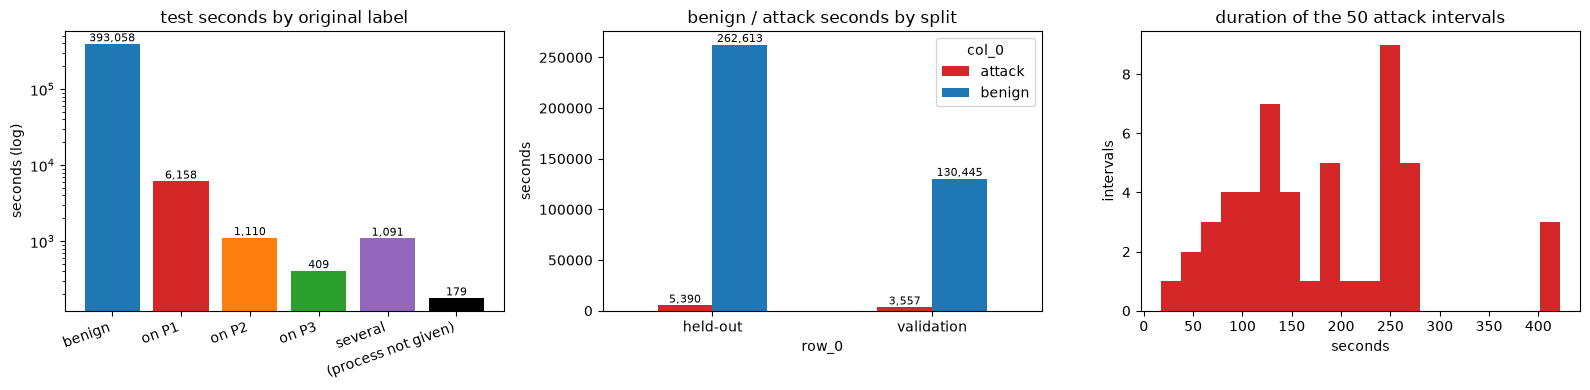

attack duration: min 17 s, median 162 s, max 422 s


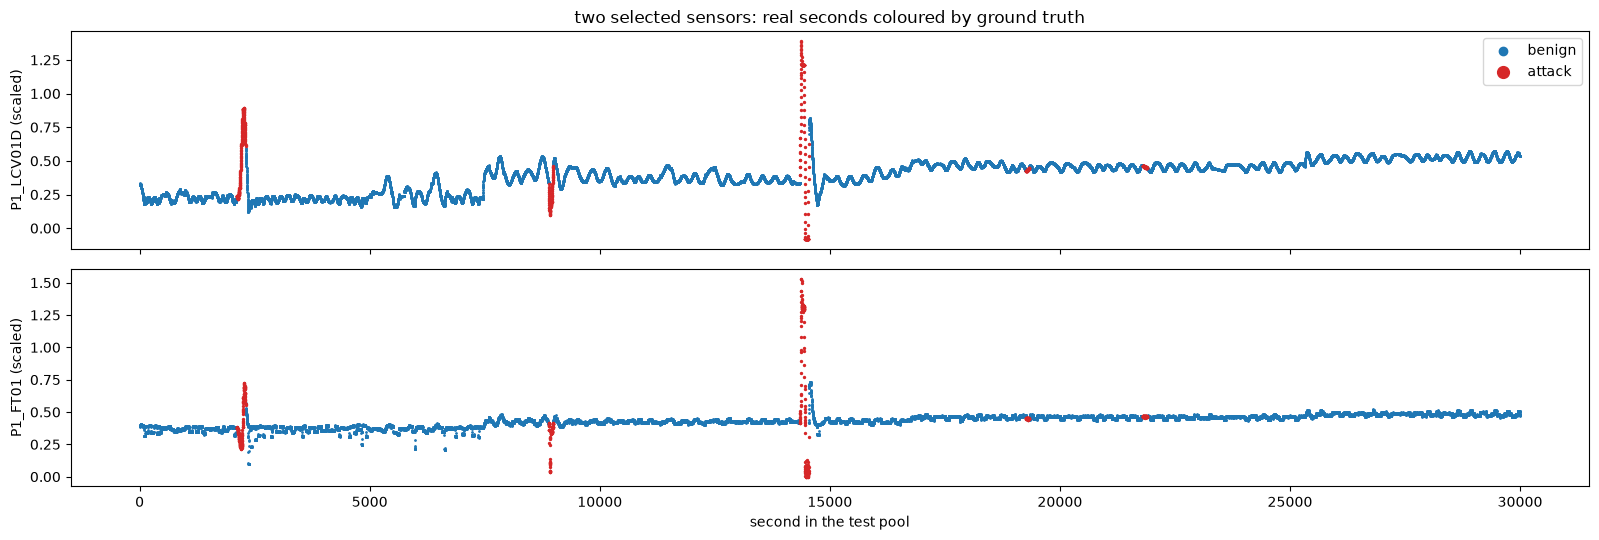

In [6]:
# class distribution: seconds per label (pooled test data), per split, and attack intervals per process
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cnt = pd.Series(fam).value_counts().reindex(FAM_ORDER).dropna()
ax[0].bar(range(len(cnt)), cnt.values, color=[FAM_COL[k] for k in cnt.index]); ax[0].set_yscale("log"); ax[0].set_xticks(range(len(cnt)))
ax[0].set_xticklabels([k.replace("attack on several processes", "several").replace("attack ", "") for k in cnt.index], rotation=20, ha="right")
for i, v in enumerate(cnt.values): ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)
ax[0].set_title("test seconds by original label"); ax[0].set_ylabel("seconds (log)")
sp = pd.crosstab(np.where(np.arange(len(Yte)) < CUT, "validation", "held-out"), np.where(y_all == 1, "attack", "benign"))
sp.plot.bar(ax=ax[1], color=["tab:red", "tab:blue"], rot=0); ax[1].set_title("benign / attack seconds by split"); ax[1].set_ylabel("seconds")
for p in ax[1].patches: ax[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=8)
R_all = np.c_[np.where(np.diff(np.r_[0, y_all, 0]) == 1)[0], np.where(np.diff(np.r_[0, y_all, 0]) == -1)[0] - 1]
dur = R_all[:, 1] - R_all[:, 0] + 1
ax[2].hist(dur, bins=20, color="tab:red"); ax[2].set_title("duration of the %d attack intervals" % len(dur)); ax[2].set_xlabel("seconds"); ax[2].set_ylabel("intervals")
plt.tight_layout(); plt.show()
print("attack duration: min %d s, median %d s, max %d s" % (dur.min(), np.median(dur), dur.max()))

# the two most important sensors over a stretch of the first test file (every point is a real second coloured by its ground-truth label)
seg = slice(0, min(30000, len(Xte)))
fig, ax = plt.subplots(2, 1, figsize=(16, 5.5), sharex=True)
t = np.arange(len(Xte))[seg]
for a, j in zip(ax, [0, 2]):
    b = fam[seg] == "benign"
    a.scatter(t[b], Xte[seg][b, j], s=1, c="tab:blue", label="benign"); a.scatter(t[~b], Xte[seg][~b, j], s=2, c="tab:red", label="attack")
    a.set_ylabel(FEAT_SEL[j] + " (scaled)")
ax[0].legend(markerscale=6, loc="upper right"); ax[1].set_xlabel("second in the test pool"); ax[0].set_title("two selected sensors: real seconds coloured by ground truth")
plt.tight_layout(); plt.show()


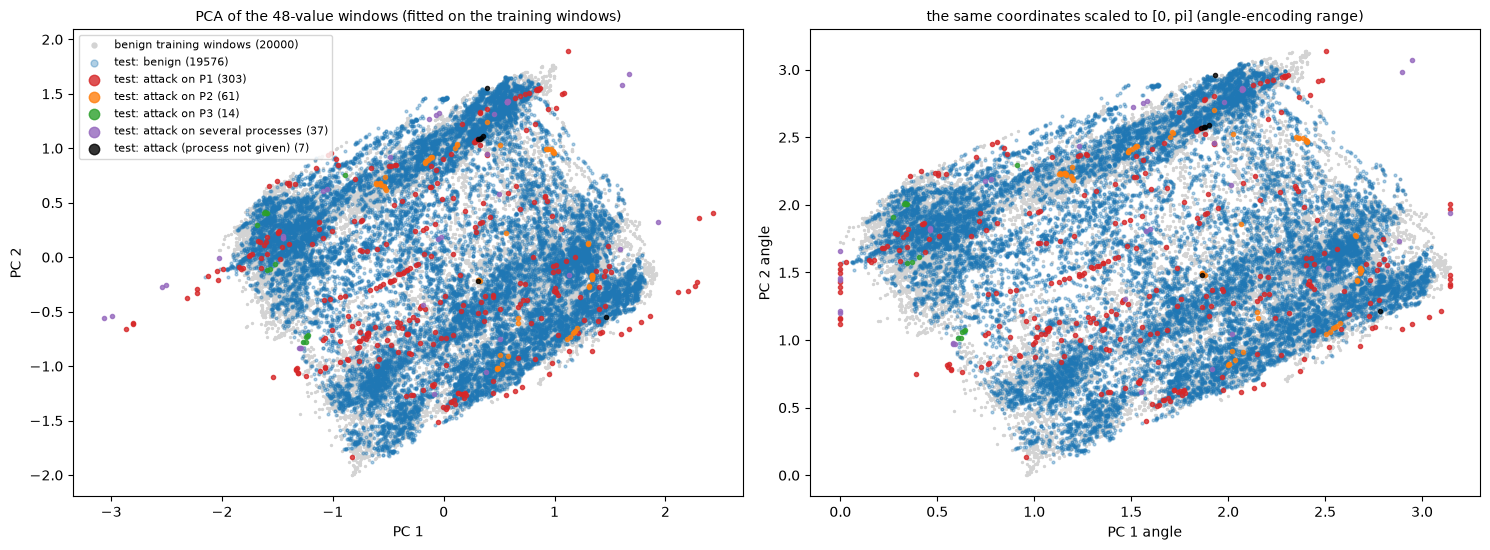

explained variance of the two PCA axes: [0.416 0.236] | test windows outside the training PCA box (clipped to [0, pi]): 22 of 19998


In [7]:
# scatter of the real 3-second windows (48 values) coloured by the ground-truth label of the target second
rngp = np.random.default_rng(SEED)
pos = np.sort(rngp.choice(np.arange(TAU, len(Xte)), size=min(20000, len(Xte) - TAU), replace=False))
ok = (fid[pos] == fid[pos - TAU])                                                  # window inside one file
pos = pos[ok]
Wte_s = np.stack([Xte[pos - 3], Xte[pos - 2], Xte[pos - 1]], 1).reshape(len(pos), -1)
Wtr_s = D["Wtr_sub"][:, :TAU * N_FEAT].astype(np.float64)                         # real training windows (benign)
pca = PCA(n_components=2, random_state=SEED).fit(Wtr_s)
P_tr, P_te = pca.transform(Wtr_s), pca.transform(Wte_s)
sc = MinMaxScaler((0, np.pi)).fit(P_tr)
S_tr, S_te = sc.transform(P_tr), np.clip(sc.transform(P_te), 0, np.pi)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6))
for a, (A_tr, A_te, ttl, xl, yl) in zip(ax, [(P_tr, P_te, "PCA of the 48-value windows (fitted on the training windows)", "PC 1", "PC 2"),
                                           (S_tr, S_te, "the same coordinates scaled to [0, pi] (angle-encoding range)", "PC 1 angle", "PC 2 angle")]):
    a.scatter(A_tr[:, 0], A_tr[:, 1], s=2, c="lightgrey", label=f"benign training windows ({len(A_tr)})", zorder=1)
    for k in FAM_ORDER:
        m = fam[pos] == k
        if m.any(): a.scatter(A_te[m, 0], A_te[m, 1], s=4 if k == "benign" else 9, c=FAM_COL[k], alpha=.35 if k == "benign" else .8, label=f"test: {k} ({m.sum()})", zorder=2 if k == "benign" else 3)
    a.set_title(ttl, fontsize=10); a.set_xlabel(xl); a.set_ylabel(yl)
ax[0].legend(markerscale=2.5, fontsize=8, loc="best"); plt.tight_layout(); plt.show()
print("explained variance of the two PCA axes:", pca.explained_variance_ratio_.round(3), "| test windows outside the training PCA box (clipped to [0, pi]):", int(((sc.transform(P_te) < 0) | (sc.transform(P_te) > np.pi)).any(1).sum()), "of", len(P_te))


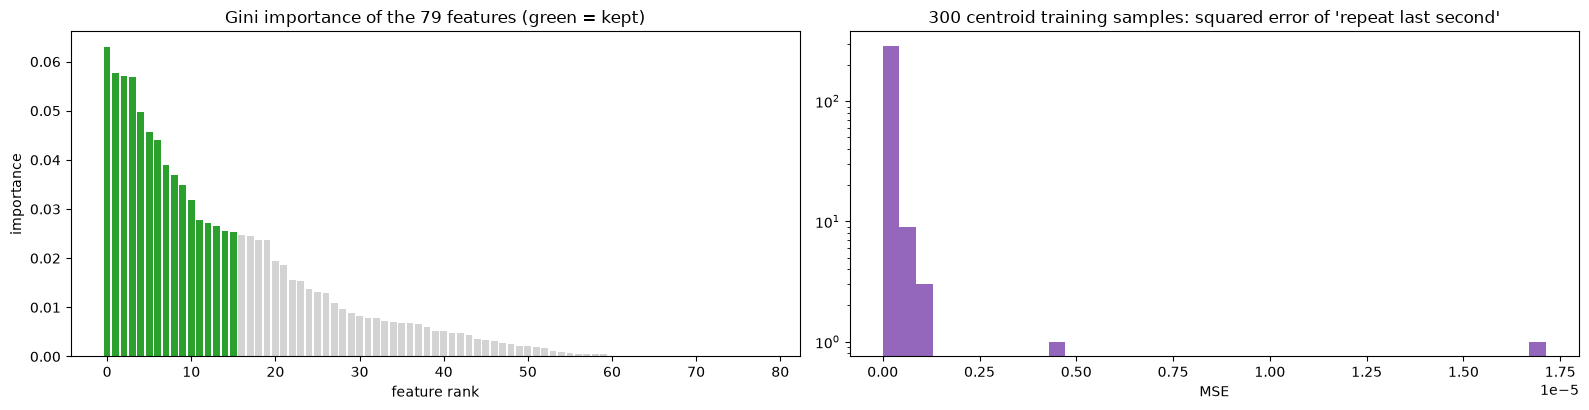

training windows: 230400 -> 300 centroids | persistence (repeat the last second) MSE on the centroids: 1.62e-07, predict-the-mean MSE: 4.76e-02


In [8]:
# Gini importance of all features (analogue of the paper's Fig. 1) and the K-Means summary of the training windows
fig, ax = plt.subplots(1, 2, figsize=(16, 4.2))
order = np.argsort(-D["imp"])
ax[0].bar(range(len(order)), D["imp"][order], color=["tab:green" if i in set(top) else "lightgrey" for i in order]); ax[0].set_title("Gini importance of the %d features (green = kept)" % len(feat))
ax[0].set_xlabel("feature rank"); ax[0].set_ylabel("importance")
ax[1].hist(((Wc[:, -1] - yc) ** 2).mean(1), bins=40, color="tab:purple")
ax[1].set_title("%d centroid training samples: squared error of 'repeat last second'" % len(Wc)); ax[1].set_xlabel("MSE"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()
print("training windows:", int(D["n_windows"]), "-> %d centroids | persistence (repeat the last second) MSE on the centroids: %.2e, predict-the-mean MSE: %.2e" % (len(Wc), ((Wc[:, -1] - yc) ** 2).mean(), ((yc.mean(0) - yc) ** 2).mean()))


## 2. The metric: enhanced time-series aware precision and recall (eTaPR)

Point-wise F1 rewards a detector for flagging single seconds, although an attack is an *interval*. Hwang et al. (SAC 2022) define, for the ground-truth attack
ranges `A_i` and the predicted ranges `P_j`:

- the overlap matrix between ranges; ranges whose overlap is too small are **pruned** (a real attack covered by less than `theta_r = 0.1` of its length counts as missed,
  a predicted range that overlaps real attacks by less than `theta_p = 0.5` of its length counts as a false alarm);
- **eTaR** = mean over attacks of `(d + d * p) / 2`, with `d` = 1 if the attack is detected (coverage >= theta_r) and `p` = covered fraction;
- **eTaP** = length-weighted (square root of the length) mean over predicted ranges of `(d + d * p) / 2`, `d` = 1 if the range is mostly correct (>= theta_p), `p` = correct fraction;
- **TaF1** = harmonic mean of eTaP and eTaR.

The paper (like the HAI competition) uses `theta_p = 0.5`, `theta_r = 0.1` and no ambiguous region (`delta = 0`). The vectorised implementation below is checked against a literal, loop-based
transcription of the reference package (`wshw4ng/eTaPR`, `etapr.py` and `tapr.py`) on random streams.

In [9]:
def label_ranges(y):
    """Binary per-second labels -> array of [first, last] indices of the 1-runs."""
    y = np.asarray(y).astype(int); d = np.diff(np.r_[0, y, 0])
    return np.c_[np.where(d == 1)[0], np.where(d == -1)[0] - 1]

def etapr(y_true, y_pred, theta_p=THETA_P, theta_r=THETA_R):
    """eTaP, eTaR and TaF1 (Hwang et al., SAC 2022) for binary point labels, delta = 0 (no ambiguous region). Vectorised."""
    A, P = label_ranges(y_true), label_ranges(y_pred)
    if len(A) == 0 or len(P) == 0: return dict(eTaP=0.0, eTaR=0.0, TaF1=0.0, n_pred=len(P), n_true=len(A))
    la, lp = (A[:, 1] - A[:, 0] + 1).astype(float), (P[:, 1] - P[:, 0] + 1).astype(float)
    m = np.maximum(0, np.minimum(A[:, None, 1], P[None, :, 1]) - np.maximum(A[:, None, 0], P[None, :, 0]) + 1).astype(float)
    while True:                                               # pruning of weak overlaps
        tars = m.sum(1) / la; ra = (tars < theta_r) & (tars > 0); m[ra, :] = 0
        taps = m.sum(0) / lp; rp = (taps < theta_p) & (taps > 0); m[:, rp] = 0
        if not ra.any() and not rp.any(): break
    tars = m.sum(1) / la; d = (tars >= theta_r).astype(float)
    eTaR = float(np.mean((d + d * np.minimum(tars, 1.0)) / 2))
    taps = m.sum(0) / lp; d = (taps >= theta_p).astype(float); w = np.sqrt(lp)          # predicted ranges weighted by sqrt(length)
    eTaP = float(np.sum(w * (d + d * taps) / 2) / w.sum())
    f1 = 0.0 if eTaP + eTaR == 0 else 2 * eTaP * eTaR / (eTaP + eTaR)
    return dict(eTaP=eTaP, eTaR=eTaR, TaF1=float(f1), n_pred=len(P), n_true=len(A))

def etapr_reference(y_true, y_pred, theta_p=0.5, theta_r=0.1):
    """Slow, loop-based transcription of the reference eTaPR code (class eTaPR in etapr.py) with delta = 0."""
    A = [tuple(r) for r in label_ranges(y_true)]; P = [tuple(r) for r in label_ranges(y_pred)]
    if not A or not P: return 0.0, 0.0
    ov = np.zeros((len(A), len(P)))
    for i, (a0, a1) in enumerate(A):
        for j, (p0, p1) in enumerate(P):
            s, e = max(a0, p0), min(a1, p1)
            ov[i, j] = float(sum(1.0 for _ in range(s, e + 1))) if e >= s else 0.0      # sum of the uniform function over the overlap
    max_a = [float(a1 - a0 + 1) for a0, a1 in A]; max_p = [p1 - p0 + 1 for p0, p1 in P]
    wts = [math.sqrt(p1 - p0 + 1) for p0, p1 in P]
    m = ov.copy()
    while True:
        tars = m.sum(axis=1) / max_a
        ea = set(np.where(tars < theta_r)[0]) - set(np.where(tars == 0.0)[0])
        for i in ea: m[i] = np.zeros(len(P))
        taps = m.sum(axis=0) / max_p
        ep = set(np.where(taps < theta_p)[0]) - set(np.where(taps == 0.0)[0])
        for j in ep: m[:, j] = np.zeros(len(A))
        if len(ea) == 0 and len(ep) == 0: break
    sc = m.sum(axis=1) / max_a
    det = np.where(sc >= theta_r, 1.0, 0.0); por = np.where(sc > 1.0, 1.0, sc)
    etar = ((det + det * por) / 2).mean()
    sc = m.sum(axis=0) / max_p
    det = np.where(sc >= theta_p, 1.0, 0.0); s = (det + det * sc) / 2
    etap = sum(wts[i] * s[i] for i in range(len(P))) / sum(wts)
    return etap, etar

rs = np.random.default_rng(0)
def rand_stream(n=400):
    y = np.zeros(n, int)
    for _ in range(rs.integers(1, 6)):
        a = rs.integers(0, n - 5); y[a:a + rs.integers(3, 60)] = 1
    return y
for _ in range(40):
    yt, yp = rand_stream(), rand_stream()
    if rs.random() < 0.5: yp = np.where(rs.random(400) < 0.15, 1 - yp, yp)             # noisy copies of the truth give richer overlaps
    r = etapr(yt, yp); rp_, rr_ = etapr_reference(yt, yp)
    assert abs(r["eTaP"] - rp_) < 1e-12 and abs(r["eTaR"] - rr_) < 1e-12, (r, rp_, rr_)
print("vectorised eTaPR == literal transcription of the reference code on 40 random stream pairs")
print("sanity checks: perfect prediction ->", {k: round(v, 3) for k, v in etapr(y_all[:50000], y_all[:50000]).items() if k.startswith(("e", "Ta"))},
      "| nothing flagged ->", etapr(y_all[:50000], np.zeros(50000))["TaF1"])


vectorised eTaPR == literal transcription of the reference code on 40 random stream pairs
sanity checks: perfect prediction -> {'eTaP': 1.0, 'eTaR': 1.0, 'TaF1': 1.0} | nothing flagged -> 0.0


In [10]:
# Re-scoring the published predictions of the two RNN baselines of the paper's Table II (files of the eTaPR repository, HAI attack stream with 38 attacks).
# Different HAI version than ours and possibly different metric settings in the paper, so only a plausibility check of the metric code.
RNN_PUB = {}
try:
    base = "https://raw.githubusercontent.com/wshw4ng/eTaPR/master/Sample_Data/Real%20Data/hai/"
    rd = lambda f: (np.array(requests.get(base + f, timeout=60).text.split(), dtype=int) == -1).astype(int)
    y_pub = rd("HAI_Attack_Stream.csv")
    for nm, f in [("RNNv1", "rnn_v1.csv"), ("RNNv2", "rnn_v2.csv")]: RNN_PUB[nm] = etapr(y_pub, rd(f))
    print(f"HAI attack stream of the eTaPR repository: {len(y_pub):,} s, {len(label_ranges(y_pub))} attacks")
    for nm, r in RNN_PUB.items(): print(f"  {nm}: eTaP {r['eTaP']:.3f}  eTaR {r['eTaR']:.3f}  TaF1 {r['TaF1']:.3f}")
    print("  paper's Table II (from Hwang et al.): RNNv1 0.90 / 0.84 / 0.83, RNNv2 0.75 / 0.69 / 0.78")
except Exception as e:
    print("published RNN predictions not available:", repr(e)[:100])


HAI attack stream of the eTaPR repository: 440,335 s, 38 attacks
  RNNv1: eTaP 0.771  eTaR 0.799  TaF1 0.785
  RNNv2: eTaP 0.505  eTaR 0.722  TaF1 0.594
  paper's Table II (from Hwang et al.): RNNv1 0.90 / 0.84 / 0.83, RNNv2 0.75 / 0.69 / 0.78


## 3. The quantum models: how they are simulated

**One hybrid quantum layer (HQL)** (paper Fig. 2): a dense layer maps the input to 30 numbers `h`; the 5-qubit circuit starts in `|00000>` and applies, for each of the **6 blocks**,
`RY(arctan h_{l,q})` on every qubit `q` (**successive data injection**: block `l` receives the next five numbers), then `RZ(theta_{l,q,0})` and `RX(theta_{l,q,1})` on every qubit and a ring of CNOTs
`0->1, 1->2, 2->3, 3->4, 4->0`. The outputs are the expectation values `<Z_q>` of the five qubits, followed by a dense layer. The circuit has **60 trainable angles**, 30 data angles, 5 qubits.

**QGRU**: `z = sigmoid(HQL_z([x, h]))`, `r = sigmoid(HQL_r([x, h]))`, `c = tanh(HQL_c([x, r*h]))`, `h' = (1-z) h + z c`.
**Generator**: QGRU over the 3-second window, then two parallel HQLs for `mu` and `log sigma^2`. **Critic**: QGRU over the window plus the candidate point (4 steps), then an HQL to a scalar.

**Simulator.** PennyLane executes one small circuit at a time, which is far too slow for batches of hundreds of circuits with second-order gradients (gradient penalty). The notebook therefore uses a
differentiable PyTorch **exact state-vector simulator**: the RY data layer of all samples is a Kronecker product of single-qubit matrices, the data-independent `RZ-RX-CNOT` layer is a
single 32 x 32 matrix per block, and the final probabilities give `<Z_q>`. The next section **asserts that this simulator equals the PennyLane QNode** for random angles and for
explicit noise realisations. The noise model of the paper (random Pauli X/Y/Z errors with probability 0.1 after the encoding and after the rotations of every block, CNOTs with swapped control/target with probability 0.2)
is implemented as stochastic per-circuit errors.

In [11]:
# ---- exact differentiable state-vector simulation of the 5-qubit hybrid-quantum-layer circuit (PyTorch, float64)
torch.set_default_dtype(torch.float64)
CDT = torch.complex128
NQ, NB = 5, 6          # qubits per VQC; SuDaI blocks (one encoding layer + one variational layer each = 12 alternating layers)
DIM = 2 ** NQ

def _cnot_perm(flips=None):
    """Basis-state map b -> f[b] of the CNOT ring CNOT(0,1), CNOT(1,2), ..., CNOT(4,0) (wire 0 = most significant bit).
    flips[q]=1 swaps control and target of the q-th gate (the 'flipped control-target CNOT' error of the paper's noise model)."""
    f = np.zeros(DIM, dtype=int)
    for b in range(DIM):
        bits = [(b >> (NQ - 1 - q)) & 1 for q in range(NQ)]
        for q in range(NQ):
            c, t = q, (q + 1) % NQ
            if flips is not None and flips[q]: c, t = t, c
            if bits[c]: bits[t] ^= 1
        f[b] = sum(bit << (NQ - 1 - q) for q, bit in enumerate(bits))
    return f

CNOT_M = torch.zeros(DIM, DIM, dtype=CDT); CNOT_M[torch.tensor(_cnot_perm()), torch.arange(DIM)] = 1
_INV = torch.zeros(2 ** NQ, DIM, dtype=torch.long)            # for each of the 32 flip patterns: new_state = state[_INV[k]]
for _k in range(2 ** NQ):
    _f = _cnot_perm([(_k >> q) & 1 for q in range(NQ)]); _inv = np.empty(DIM, dtype=int); _inv[_f] = np.arange(DIM); _INV[_k] = torch.tensor(_inv)
SIGN = torch.stack([1 - 2 * ((torch.arange(DIM) >> (NQ - 1 - q)) & 1) for q in range(NQ)], 1).to(torch.get_default_dtype())   # (32, 5) eigenvalues of Z_q
_IDX = torch.arange(DIM)

def kron_stack(m):
    """m: (..., n, 2, 2) -> (..., 2^n, 2^n) Kronecker product over the qubit axis (first qubit = most significant)."""
    U = m[..., 0, :, :]
    for q in range(1, m.shape[-3]):
        d = U.shape[-1]
        U = (U[..., :, None, :, None] * m[..., q, None, :, None, :]).reshape(*U.shape[:-2], d * 2, d * 2)
    return U

def rot_unitary(th):
    """th: (..., NQ, 2) = (RZ angle, RX angle) per qubit -> (..., 32, 32) complex: tensor product of RX(b) @ RZ(a) (RZ first)."""
    a, b = th[..., 0], th[..., 1]
    z = torch.zeros_like(a).to(CDT)
    rz = torch.stack([torch.stack([torch.exp(-0.5j * a), z], -1), torch.stack([z, torch.exp(0.5j * a)], -1)], -2)
    cb, sb = torch.cos(b / 2).to(CDT), torch.sin(b / 2).to(CDT)
    rx = torch.stack([torch.stack([cb, -1j * sb], -1), torch.stack([-1j * sb, cb], -1)], -2)
    return kron_stack(rx @ rz)

def to_block(U):
    """complex (..., 32, 32) -> real (..., 64, 64) acting on the stacked [re; im] state vector."""
    return torch.cat([torch.cat([U.real, -U.imag], -1), torch.cat([U.imag, U.real], -1)], -2)

def ry_layers(ang):
    """ang: (N, NB, NQ) -> the RY(ang) layer of every block as two real matrices: qubits 0-2 (8x8) and qubits 3-4 (4x4)."""
    c, s = torch.cos(ang / 2), torch.sin(ang / 2)
    m = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)          # (N, NB, NQ, 2, 2)
    return kron_stack(m[:, :, :3]), kron_stack(m[:, :, 3:])

def apply_ry(S, MA, MB):
    """S: (N, 2, 32) real [re; im]; MA (N, 8, 8), MB (N, 4, 4): product of the single-qubit RY gates on qubits 0-2 and 3-4."""
    N = S.shape[0]
    v = torch.matmul(MA[:, None], S.reshape(N, 2, 8, 4))                 # (N, 2, 8, 4)
    return torch.matmul(v.reshape(N, 16, 4), MB.transpose(1, 2)).reshape(N, 2, DIM)

def pauli_error(S, pauli):
    """Apply per sample a tensor product of Pauli errors (0=I, 1=X, 2=Y, 3=Z per qubit) to S (N, 2, 32) = [re; im]."""
    qs = torch.arange(NQ)
    xm = (((pauli == 1) | (pauli == 2)).long() * (2 ** (NQ - 1 - qs))).sum(-1)
    zb = ((pauli == 2) | (pauli == 3)).long()
    ny = (pauli == 2).sum(-1)
    src = _IDX[None, :] ^ xm[:, None]
    sgn = 1 - 2 * ((zb[:, None, :] * ((src[:, :, None] >> (NQ - 1 - qs)) & 1)).sum(-1) % 2)
    psi = torch.complex(S[:, 0], S[:, 1])
    psi = torch.gather(psi, 1, src) * sgn.to(CDT) * torch.exp(0.5j * math.pi * ny)[:, None]
    return torch.stack([psi.real, psi.imag], 1)

class _Noise:
    on = False; gen = torch.Generator()
NOISE = _Noise()

def sample_noise(N, gen, p1=0.1, p2=0.2):
    """Stochastic Pauli errors: after every encoding layer and every rotation layer each qubit suffers X/Y/Z with probability p1;
    every CNOT of the ring is applied with control and target flipped with probability p2."""
    err = (torch.rand(N, NB, 2, NQ, generator=gen) < p1).long()
    which = torch.randint(1, 4, (N, NB, 2, NQ), generator=gen)
    flips = (torch.rand(N, NB, NQ, generator=gen) < p2).long()
    return dict(pauli=err * which, flip=(flips * (2 ** torch.arange(NQ))).sum(-1))


In [12]:
# ---- the hybrid quantum layer (HQL) and the quantum GRU
class VQC(torch.nn.Module):
    """G independent 5-qubit SuDaI circuits evaluated together. Per block l = 1..6:  RY(arctan h_{l,q}) on every qubit q (data injection),
    then RZ(theta_{l,q,0}), RX(theta_{l,q,1}) on every qubit, then the CNOT ring. Output: <Z_q> of every qubit."""
    def __init__(self, G=1):
        super().__init__()
        self.G = G
        self.theta = torch.nn.Parameter(0.1 * torch.randn(G, NB, NQ, 2))
    def unitary(self, noisy=None):
        """Data-independent part: for every block the rotations (and, without noise, the CNOT ring) as real (G, NB, 64, 64) matrices."""
        if NOISE.on if noisy is None else noisy: return to_block(rot_unitary(self.theta)).transpose(-1, -2)
        return to_block(CNOT_M @ rot_unitary(self.theta)).transpose(-1, -2)
    def forward(self, h, noise=None, Ub=None):
        """h: (G, B, NB*NQ) raw latent (the circuit applies arctan) -> (G, B, NQ).  noise: None or dict from sample_noise (N = G*B)."""
        G, B = h.shape[0], h.shape[1]; N = G * B
        if noise is None and NOISE.on: noise = sample_noise(N, NOISE.gen)
        MA, MB = ry_layers(torch.atan(h).reshape(N, NB, NQ))
        S = torch.zeros(N, 2, DIM); S[:, 0, 0] = 1                                   # |0...0>
        if Ub is None: Ub = self.unitary(noise is not None)
        if noise is None:
            for l in range(NB):
                S = apply_ry(S, MA[:, l], MB[:, l]).reshape(G, B, 2 * DIM)
                S = torch.matmul(S, Ub[:, l]).reshape(N, 2, DIM)
        else:
            Rb = Ub
            for l in range(NB):
                S = apply_ry(S, MA[:, l], MB[:, l])
                S = pauli_error(S, noise["pauli"][:, l, 0])                          # error after the data encoding
                S = torch.matmul(S.reshape(G, B, 2 * DIM), Rb[:, l]).reshape(N, 2, DIM)
                S = pauli_error(S, noise["pauli"][:, l, 1])                          # error after the parameterised rotations
                S = torch.gather(S, 2, _INV[noise["flip"][:, l]][:, None, :].expand(N, 2, DIM))   # CNOT ring (some gates flipped)
        return ((S[:, 0] ** 2 + S[:, 1] ** 2) @ SIGN).reshape(G, B, NQ)

class HQL(torch.nn.Module):
    """Hybrid quantum layer (G copies): Linear(n_in -> 30) -> VQC with successive data injection -> <Z> of 5 qubits -> Linear(5 -> n_out)."""
    def __init__(self, n_in, n_out, G=1):
        super().__init__()
        self.G = G
        k1, k2 = 1 / math.sqrt(n_in), 1 / math.sqrt(NQ)
        self.w1 = torch.nn.Parameter((torch.rand(G, n_in, NB * NQ) * 2 - 1) * k1); self.b1 = torch.nn.Parameter((torch.rand(G, 1, NB * NQ) * 2 - 1) * k1)
        self.vqc = VQC(G)
        self.w2 = torch.nn.Parameter((torch.rand(G, NQ, n_out) * 2 - 1) * k2); self.b2 = torch.nn.Parameter((torch.rand(G, 1, n_out) * 2 - 1) * k2)
    def forward(self, x, Ub=None):              # x: (B, n_in) shared by the G copies, or (G, B, n_in)
        if x.dim() == 2: x = x.unsqueeze(0).expand(self.G, -1, -1)
        return self.vqc(torch.matmul(x, self.w1) + self.b1, Ub=Ub) @ self.w2 + self.b2        # (G, B, n_out)

class QGRU(torch.nn.Module):
    """GRU in which the update, reset and candidate gates are hybrid quantum layers."""
    def __init__(self, n_in, n_h):
        super().__init__()
        self.nh = n_h
        self.zr = HQL(n_in + n_h, n_h, G=2)       # update and reset gates (same input) evaluated together
        self.cand = HQL(n_in + n_h, n_h, G=1)
    def forward(self, x):                         # x: (B, T, n_in) -> last hidden state (B, n_h)
        h = torch.zeros(x.shape[0], self.nh)
        U_zr, U_c = self.zr.vqc.unitary(), self.cand.vqc.unitary()            # the variational layers do not depend on the data: build once
        for t in range(x.shape[1]):
            xt = x[:, t]
            g = torch.sigmoid(self.zr(torch.cat([xt, h], -1), U_zr))
            z, r = g[0], g[1]
            c = torch.tanh(self.cand(torch.cat([xt, r * h], -1), U_c)[0])
            h = (1 - z) * h + z * c
        return h


In [13]:
# ---- generator and critic (quantum) and their classical twins
class QGenerator(torch.nn.Module):
    """QGRU backbone + two parallel HQL heads giving the Gaussian parameters mu_t and log sigma_t^2 of the next time step."""
    def __init__(self, d, n_h):
        super().__init__()
        self.rnn, self.heads = QGRU(d, n_h), HQL(n_h, d, G=2)
    def forward(self, W):                         # W: (B, T, d)
        o = self.heads(self.rnn(W))
        return o[0], o[1].clamp(-8.0, 2.0)        # CHOICE: log-variance clamped to [-8, 2]

class QCritic(torch.nn.Module):
    """QGRU over the window followed by the candidate next point, then an HQL that outputs the Wasserstein score."""
    def __init__(self, d, n_h):
        super().__init__()
        self.rnn, self.head = QGRU(d, n_h), HQL(n_h, 1, G=1)
    def forward(self, W, y):
        return self.head(self.rnn(torch.cat([W, y[:, None, :]], 1)))[0, :, 0]

class CGenerator(torch.nn.Module):
    """Classical twin: nn.GRU + two linear heads (same interface)."""
    def __init__(self, d, n_h):
        super().__init__()
        self.rnn = torch.nn.GRU(d, n_h, batch_first=True); self.mu = torch.nn.Linear(n_h, d); self.lv = torch.nn.Linear(n_h, d)
    def forward(self, W):
        h = self.rnn(W)[0][:, -1]
        return self.mu(h), self.lv(h).clamp(-8.0, 2.0)

class CCritic(torch.nn.Module):
    def __init__(self, d, n_h):
        super().__init__()
        self.rnn = torch.nn.GRU(d, n_h, batch_first=True); self.out = torch.nn.Linear(n_h, 1)
    def forward(self, W, y):
        return self.out(self.rnn(torch.cat([W, y[:, None, :]], 1))[0][:, -1])[:, 0]


## Quantum Circuit Architecture

The same 5-qubit circuit is used by **every** hybrid quantum layer of the generator and the critic (update gate, reset gate, candidate gate, `mu` head, `log sigma^2` head, critic head); only the angles differ.
Below it is built as a PennyLane QNode (`default.qubit`), drawn with `qml.draw_mpl` (6 blocks: RY data injection, RZ, RX, CNOT ring), and compared with the PyTorch simulator that is used for training.
A second drawing shows one **noisy realisation** of the same circuit (inserted Pauli errors and a flipped CNOT), which is what the noisy simulator executes.

**Assumptions where the paper omits circuit details** (also in the table at the top): the rotation order inside a block is `RZ` then `RX` (Fig. 2 lists `Rz(theta_1) Rx(theta_2)`);
the CNOT ring closes from the last qubit to the first; `RY(arctan h)` encodes the dense-layer output (Fig. 2) although Table I names `arccos(x)` as "rotation encoding" for the scaled input; 12 alternating layers = 6 x (encoding + variational);
the circuit is applied to `|0...0>`; outputs are the five single-qubit `<Z>`.

noiseless: max |torch simulator - PennyLane| = 7.771561172376096e-16


with explicit noise realisations (220 Pauli errors, 170 flipped CNOTs): max |difference| = 8.049116928532385e-16


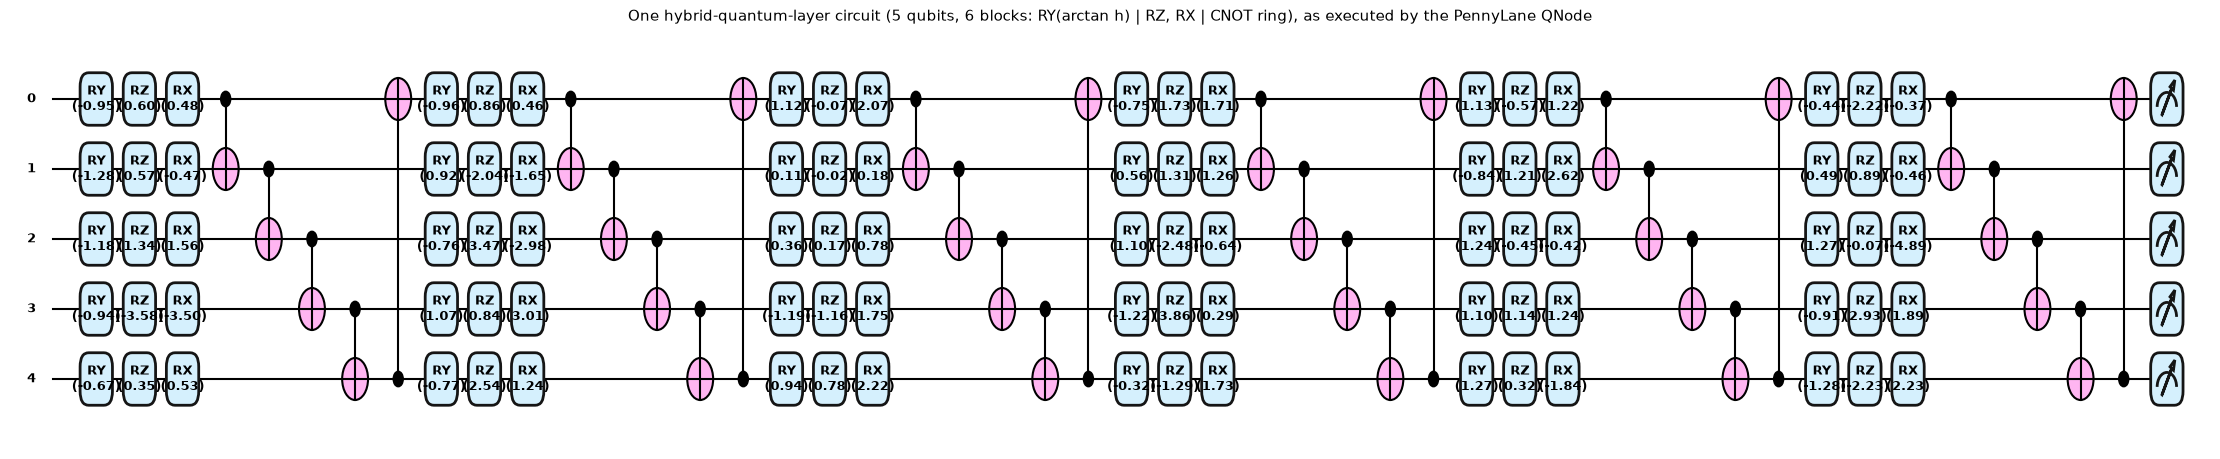

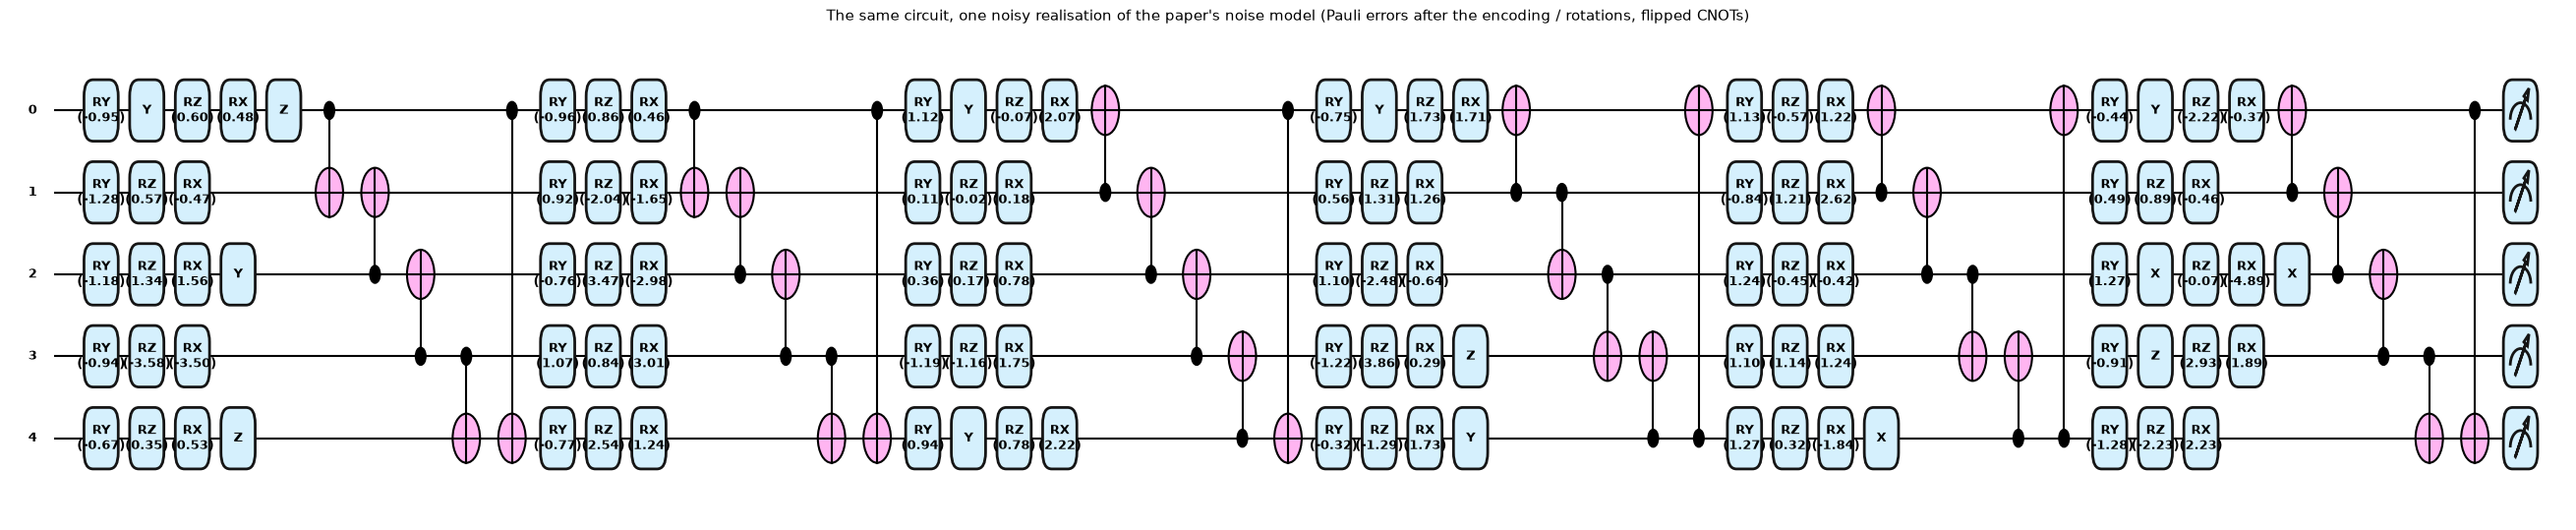

qubits: 5 | circuit depth (noiseless): 48 | gates: {'RY': 30, 'RZ': 30, 'RX': 30, 'CNOT': 30}
trainable circuit parameters per HQL: 60 (= 6 blocks x 5 qubits x 2 angles) | data-injection angles per circuit: 30


In [14]:
def pl_circuit(theta, ang, paulis=None, flips=None):
    """The PennyLane definition of one VQC (theta: (6,5,2); ang: (6,5) = arctan of the dense-layer output; optional explicit noise realisation)."""
    PAULI_GATES = [None, qml.PauliX, qml.PauliY, qml.PauliZ]
    for l in range(NB):
        for q in range(NQ): qml.RY(ang[l, q], wires=q)                                    # successive data injection
        if paulis is not None:
            for q in range(NQ):
                if paulis[l, 0, q]: PAULI_GATES[int(paulis[l, 0, q])](wires=q)             # error after the encoding
        for q in range(NQ): qml.RZ(theta[l, q, 0], wires=q); qml.RX(theta[l, q, 1], wires=q)
        if paulis is not None:
            for q in range(NQ):
                if paulis[l, 1, q]: PAULI_GATES[int(paulis[l, 1, q])](wires=q)             # error after the rotations
        for q in range(NQ):
            c, t = q, (q + 1) % NQ
            if flips is not None and (int(flips[l]) >> q) & 1: c, t = t, c                 # flipped control/target
            qml.CNOT(wires=[c, t])
    return [qml.expval(qml.PauliZ(q)) for q in range(NQ)]

dev_pl = qml.device("default.qubit", wires=NQ)
qnode = qml.QNode(pl_circuit, dev_pl)

# ---- equivalence of the PyTorch simulator and the PennyLane QNode (random angles; G = 2 independent circuits; noiseless and with explicit noise)
tg = torch.Generator().manual_seed(SEED)
vq = VQC(G=2); vq.theta.data = 2 * torch.randn(2, NB, NQ, 2, generator=tg)
hh = 2 * torch.randn(2, 6, NB * NQ, generator=tg)
out_t = vq(hh).detach().numpy()
th_np, ang_np = vq.theta.detach().numpy(), np.arctan(hh.numpy()).reshape(2, 6, NB, NQ)
out_pl = np.array([[qnode(th_np[g], ang_np[g, b]) for b in range(6)] for g in range(2)])
print("noiseless: max |torch simulator - PennyLane| =", np.abs(out_t - out_pl).max()); assert np.abs(out_t - out_pl).max() < 1e-10
nz = sample_noise(12, tg, p1=0.3, p2=0.5)                                      # many errors, to exercise every branch
out_tn = vq(hh, nz).detach().numpy()
out_pln = np.array([[qnode(th_np[g], ang_np[g, b], nz["pauli"][g * 6 + b].numpy(), nz["flip"][g * 6 + b].numpy()) for b in range(6)] for g in range(2)])
print("with explicit noise realisations (%d Pauli errors, %d flipped CNOTs): max |difference| =" % (int((nz["pauli"] > 0).sum()), int(sum(((nz["flip"] >> q) & 1).sum() for q in range(NQ)))), np.abs(out_tn - out_pln).max())
assert np.abs(out_tn - out_pln).max() < 1e-10

# ---- the drawing (the circuit object that is executed)
th0, ang0 = th_np[0], ang_np[0, 0]
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane", fontsize=9)(th0, ang0)
fig.set_size_inches(22, 4.2); ax.set_title("One hybrid-quantum-layer circuit (5 qubits, 6 blocks: RY(arctan h) | RZ, RX | CNOT ring), as executed by the PennyLane QNode", fontsize=11)
plt.show()
fig, ax = qml.draw_mpl(qnode, decimals=2, style="pennylane", fontsize=9)(th0, ang0, nz["pauli"][0].numpy(), nz["flip"][0].numpy())
fig.set_size_inches(26, 5); ax.set_title("The same circuit, one noisy realisation of the paper's noise model (Pauli errors after the encoding / rotations, flipped CNOTs)", fontsize=11)
plt.show()

specs = qml.specs(qnode)(th0, ang0)
res = specs["resources"]
try: depth = res.depth
except Exception: depth = None
print("qubits:", NQ, "| circuit depth (noiseless):", depth, "| gates:", dict(res.gate_types) if hasattr(res, "gate_types") else "")
print("trainable circuit parameters per HQL: %d (= 6 blocks x 5 qubits x 2 angles) | data-injection angles per circuit: %d" % (NB * NQ * 2, NB * NQ))


### Parameter counts of the models

Per hybrid quantum layer: dense input layer `n_in x 30 + 30`, circuit 60, dense output layer `5 x n_out + n_out`. The generator has 5 circuits (z, r, candidate in the QGRU, and the `mu`, `log sigma^2` heads, the latter two evaluated together), the critic 4.

In [15]:
def count(m): return sum(p.numel() for p in m.parameters())
def n_circuit_params(m): return sum(v.theta.numel() for v in m.modules() if isinstance(v, VQC))
torch.manual_seed(SEED)
G_q, D_q = QGenerator(N_FEAT, HIDDEN), QCritic(N_FEAT, HIDDEN)
G_c, D_c = CGenerator(N_FEAT, HIDDEN), CCritic(N_FEAT, HIDDEN)
print(f"quantum generator: {count(G_q):5d} parameters, of which {n_circuit_params(G_q)} are circuit angles ({sum(isinstance(v, VQC) for v in G_q.modules())} VQC modules, {sum(v.G for v in G_q.modules() if isinstance(v, VQC))} distinct 5-qubit circuits)")
print(f"quantum critic   : {count(D_q):5d} parameters, of which {n_circuit_params(D_q)} are circuit angles ({sum(v.G for v in D_q.modules() if isinstance(v, VQC))} distinct circuits)")
print(f"classical twin   : generator {count(G_c)} / critic {count(D_c)} parameters (nn.GRU + linear heads, same interface)")


quantum generator:  4770 parameters, of which 300 are circuit angles (3 VQC modules, 5 distinct 5-qubit circuits)
quantum critic   :  4014 parameters, of which 240 are circuit angles (4 distinct circuits)
classical twin   : generator 2176 / critic 1649 parameters (nn.GRU + linear heads, same interface)


## 4. Training: Wasserstein GAN with gradient penalty on the K-Means centroids

For a mini-batch of centroid samples `(window, next point)`:

1. **Critic step.** `x_hat = mu + sigma * eps` from the generator, an interpolation `x_tilde` between the real and the generated next point, and
   `L_critic = E[D(x_hat)] - E[D(x)] + lambda_gp * E[(||grad D(x_tilde)||_2 - 1)^2]` (gradient penalty; needs a second-order derivative through the circuits, which the differentiable simulator provides).
2. **Generator step.** `L_gen = -E[D(x_hat)] + E[exp(log sigma^2)] + lambda_kl * KL + lambda_rec * MSE(mu, x)`, with `KL = 0.5 E[exp(log sigma^2) + mu^2 - 1 - log sigma^2]`.
   The first three terms are the paper's loss; **the last term is our addition** (`LAM_REC`, see the table at the top). Section 6.3 trains the classical twin with and without it.

Adam with betas (0.5, 0.9); one critic step per generator step.

training the QUANTUM generator/critic: 100 steps, batch 32, lr 0.01, lambda_rec 50.0


  step    1/100 | critic +9.756 (gp 0.977) | gen adv -0.290  var 1.1300  kl 0.132  mse(mu,x) 0.3098 | 16s


  step    8/100 | critic +1.906 (gp 0.204) | gen adv -0.593  var 0.7660  kl 0.103  mse(mu,x) 0.1457 | 152s


  step   16/100 | critic +0.085 (gp 0.047) | gen adv -0.461  var 0.4944  kl 0.218  mse(mu,x) 0.0601 | 296s


  step   24/100 | critic +0.031 (gp 0.049) | gen adv -0.846  var 0.2971  kl 0.389  mse(mu,x) 0.0484 | 450s


...

  step   72/100 | critic +0.063 (gp 0.002) | gen adv -0.722  var 0.0341  kl 1.327  mse(mu,x) 0.0274 | 1477s


  step   80/100 | critic +0.063 (gp 0.003) | gen adv -0.576  var 0.0255  kl 1.469  mse(mu,x) 0.0260 | 1600s


  step   88/100 | critic +0.464 (gp 0.041) | gen adv -0.628  var 0.0189  kl 1.629  mse(mu,x) 0.0238 | 1779s


  step   96/100 | critic +0.166 (gp 0.010) | gen adv -0.573  var 0.0152  kl 1.728  mse(mu,x) 0.0243 | 1955s


done in 34.1 min


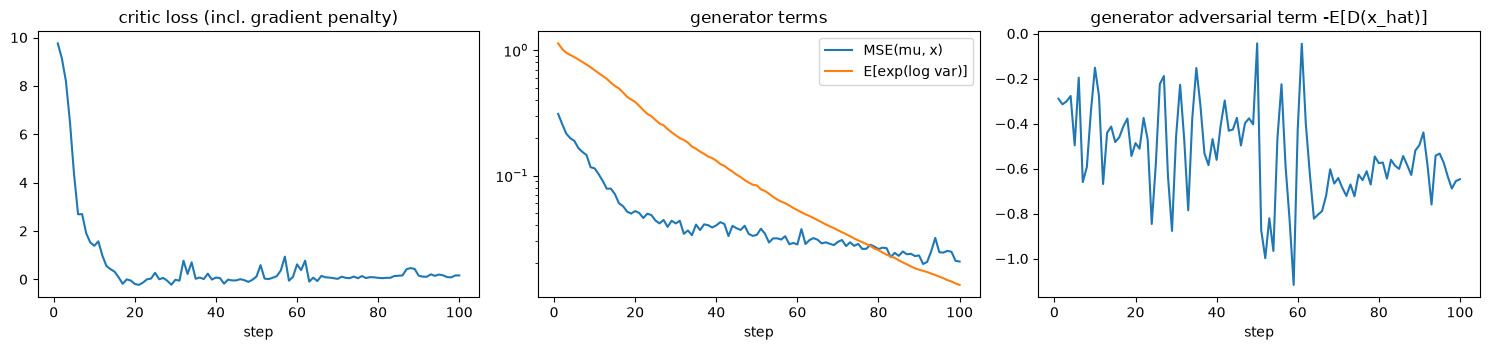

In [16]:
# the training loop (paper's losses + optional reconstruction anchor)
def reparam(mu, lv, gen=None):
    return mu + torch.exp(0.5 * lv) * torch.randn(mu.shape, generator=gen)

def train_wgan(G, D, Wc, yc, steps, batch, lr, lam_kl, lam_gp, n_critic, lam_rec, seed, log_every=25, log=print, time_budget=None):
    """Conditional WGAN-GP. Critic: E[D(fake)] - E[D(real)] + lam_gp * gradient penalty. Generator: -E[D(fake)] + E[exp(logvar)] + lam_kl * KL (+ lam_rec * MSE(mu, y))."""
    torch.manual_seed(seed); gen = torch.Generator().manual_seed(seed); rng = np.random.default_rng(seed)
    oG = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.9)); oD = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.9))   # CHOICE: WGAN-GP betas
    W = torch.tensor(Wc, dtype=torch.float64); Y = torch.tensor(yc, dtype=torch.float64); n = len(W); hist = []; t0 = time.time()
    for it in range(1, steps + 1):
        for _ in range(n_critic):
            b = torch.tensor(rng.choice(n, batch, replace=False)); w, y = W[b], Y[b]
            with torch.no_grad():
                mu, lv = G(w); fake = reparam(mu, lv, gen)
            a = torch.rand(batch, 1, generator=gen)
            xt = (a * y + (1 - a) * fake).requires_grad_(True)
            s = D(torch.cat([w, w, w]), torch.cat([y, fake, xt]))              # real, fake and interpolated points in one batch
            sr, sf, si = s[:batch], s[batch:2 * batch], s[2 * batch:]
            grad = torch.autograd.grad(si.sum(), xt, create_graph=True)[0]
            gp = ((grad.norm(dim=1) - 1) ** 2).mean()
            lossD = sf.mean() - sr.mean() + lam_gp * gp
            oD.zero_grad(); lossD.backward(); oD.step()
        b = torch.tensor(rng.choice(n, batch, replace=False)); w, y = W[b], Y[b]
        mu, lv = G(w); fake = reparam(mu, lv, gen)
        adv = -D(w, fake).mean()
        lvar = torch.exp(lv).mean(); kl = 0.5 * (torch.exp(lv) + mu ** 2 - 1 - lv).mean(); rec = ((mu - y) ** 2).mean()
        lossG = adv + lvar + lam_kl * kl + lam_rec * rec
        oG.zero_grad(); lossG.backward(); oG.step()
        hist.append((it, lossD.item(), adv.item(), lvar.item(), kl.item(), rec.item(), time.time() - t0))
        if it % log_every == 0 or it == 1:
            log(f"  step {it:4d}/{steps} | critic {lossD.item():+.3f} (gp {gp.item():.3f}) | gen adv {adv.item():+.3f}  var {lvar.item():.4f}  kl {kl.item():.3f}  mse(mu,x) {rec.item():.4f} | {time.time() - t0:.0f}s")
        if time_budget and time.time() - t0 > time_budget:
            log(f"  time budget of {time_budget}s reached after {it} steps"); break
    return pd.DataFrame(hist, columns=["step", "critic_loss", "gen_adv", "var_pen", "kl", "mse_mu", "elapsed"])

NOISE.on = False
t0 = time.time()
print(f"training the QUANTUM generator/critic: {Q_STEPS} steps, batch {BATCH}, lr {LR_Q}, lambda_rec {LAM_REC}")
hist_q = train_wgan(G_q, D_q, Wc, yc, Q_STEPS, BATCH, LR_Q, LAM_KL, LAM_GP, 1, LAM_REC, SEED, log_every=max(1, Q_STEPS // 12))
TIME_Q_TRAIN = time.time() - t0; print(f"done in {TIME_Q_TRAIN / 60:.1f} min")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(hist_q.step, hist_q.critic_loss); ax[0].set_title("critic loss (incl. gradient penalty)")
ax[1].plot(hist_q.step, hist_q.mse_mu, label="MSE(mu, x)"); ax[1].plot(hist_q.step, hist_q.var_pen, label="E[exp(log var)]"); ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_title("generator terms")
ax[2].plot(hist_q.step, hist_q.gen_adv); ax[2].set_title("generator adversarial term -E[D(x_hat)]")
for a in ax: a.set_xlabel("step")
plt.tight_layout(); plt.show()


## 5. The two-stage anomaly detector

For every second `t` the generator has predicted `mu_t` and `sigma_t` from the previous three seconds. With `kappa` a half-width in standard deviations:

1. **Interval gate** (Eq. 1): per feature `v_j = max(0, |x_j - mu_j| - kappa * sigma_j)`; `S_iv` = mean of the 3 largest `v_j`. The gate fires when `S_iv(t) > T_t`, where
   `T_t = mean + k * std` of the score over a window **centred on t** with the length `w = mu_d^p * g^(1-p)` (`mu_d` mean attack duration, `g` mean normal gap, `p` attack fraction, all taken from the validation labels), `k = 1.5`.
2. **Multi-metric score** (Eqs. 2-4): `S_topk` = mean of the 3 largest squared errors `(x_j - mu_j)^2`, `S_critic = -D(.)` (we compute the critic on the generated point `mu_t`, Eq. 2 as written, and on the
   observed point `x_t`, and choose on the validation set), both min-max normalised with the validation range; `A = S_topk + S_critic`. A second is an **alarm** when the gate fired **and** `A(t) > T'_t`
   (the same local threshold applied to `A`).

Everything that needs the labels (kappa, critic variant) is decided on the **validation** third; the held-out two thirds are only used for the final numbers.

In [17]:
@torch.no_grad()
def predict_stream(G, D, X, chunk=4096, noisy=False, seed=0, tau=TAU):
    """For every second t >= tau of the (T, d) stream X: mu_t, log sigma_t^2, the critic score of the observed point D(W, x_t) and of the generated point D(W, mu_t). Rows < tau are NaN."""
    NOISE.on = noisy; NOISE.gen = torch.Generator().manual_seed(seed)
    T, d = X.shape; mu = np.full((T, d), np.nan); lv = np.full((T, d), np.nan); dobs = np.full(T, np.nan); dgen = np.full(T, np.nan)
    idx = np.arange(tau)[None, :] + np.arange(T - tau)[:, None]
    try:
        for i in range(0, T - tau, chunk):
            w = torch.tensor(X[idx[i:i + chunk]], dtype=torch.float64); y = torch.tensor(X[tau + i: tau + i + len(w)], dtype=torch.float64)
            m, l = G(w); sl = slice(tau + i, tau + i + len(w))
            mu[sl], lv[sl] = m.numpy(), l.numpy(); dobs[sl] = D(w, y).numpy(); dgen[sl] = D(w, m).numpy()
    finally:
        NOISE.on = False
    return dict(mu=mu, lv=lv, dobs=dobs, dgen=dgen)

def predict_range(G, D, a, b, **kw):
    """Run predict_stream on Xte[a:b], file by file (a window never spans two recording files)."""
    out = None
    for f in np.unique(fid[a:b]):
        ii = np.where(fid[a:b] == f)[0]; i0, i1 = ii[0], ii[-1] + 1
        P = predict_stream(G, D, Xte[a + i0: a + i1], **kw)
        if out is None: out = {k: np.full((b - a,) + v.shape[1:], np.nan) for k, v in P.items()}
        for k in P: out[k][i0:i1] = P[k]
    return out

def topk_mean(M, k=TOPK): return np.sort(M, axis=1)[:, -k:].mean(1)
def interval_score(X, mu, lv, kappa, k=TOPK): return topk_mean(np.maximum(0.0, np.abs(X - mu) - kappa * np.exp(0.5 * lv)), k)   # Eq. (1)
def recon_score(X, mu, k=TOPK): return topk_mean((X - mu) ** 2, k)                                                           # Eq. (3)

def local_threshold(s, w, k):
    """T_t = mean + k * std of the score over a window of length w centred on t."""
    w = int(max(3, w)) | 1
    r = pd.Series(s).rolling(w, center=True, min_periods=1)
    return (r.mean() + k * r.std().fillna(0.0)).values

def window_size(y_val):
    """w = mu_d^p * g^(1-p) from the validation labels (mu_d: mean attack duration, g: mean gap between attacks, p: attack fraction)."""
    R = label_ranges(y_val); A, N = len(R), len(y_val)
    mu_d = float(np.mean(R[:, 1] - R[:, 0] + 1)); p = A * mu_d / N; g = (N - A * mu_d) / A
    return mu_d ** p * g ** (1 - p), dict(attacks=A, N=N, mu_d=round(mu_d, 1), p=round(p, 4), g=round(g, 1))

def detect(S, w, k, gate=None):
    """Alarm at t when S_t > T_t (and, if given, the gate score also exceeds its own local threshold)."""
    out = np.nan_to_num(S, nan=-np.inf) > local_threshold(np.nan_to_num(S), w, k)
    if gate is not None: out &= np.nan_to_num(gate, nan=-np.inf) > local_threshold(np.nan_to_num(gate), w, k)
    return out

W_SIZE, W_INFO = window_size(y_all[:CUT])
print(f"window size w = mu_d^p * g^(1-p) = {W_SIZE:.0f} s   from the validation labels: {W_INFO}")

def scores_of(P, X, kappa, critic):
    return dict(iv=interval_score(X, P["mu"], P["lv"], kappa), top=recon_score(X, P["mu"]), crit=-(P["dobs"] if critic == "obs" else P["dgen"]))

def variants(Sc, norm, w=None, k=K_THR):
    """The four detectors of the paper's ablation (Table III) on pre-computed scores."""
    w = W_SIZE if w is None else w
    nrm = lambda s, key: (s - norm[key][0]) / (norm[key][1] - norm[key][0] + 1e-300)
    A = nrm(Sc["top"], "top") + nrm(Sc["crit"], "crit")
    return {"Full model": detect(A, w, k, gate=Sc["iv"]), "Critic only": detect(Sc["crit"], w, k),
            "Reconstruction error only": detect(Sc["top"], w, k), "Interval violation only": detect(Sc["iv"], w, k)}, A

def norm_from(Sc): return {key: (np.nanmin(Sc[key]), np.nanmax(Sc[key])) for key in ("top", "crit")}
def row(y, pred, **extra): r = etapr(y, pred); return dict(**extra, eTaP=r["eTaP"], eTaR=r["eTaR"], TaF1=r["TaF1"], alarms=r["n_pred"], attacks=r["n_true"])

def tune_and_eval(P_val, P_held, y_val, y_held, X_val, X_held, name):
    """Choose kappa and the critic variant on the validation range, then evaluate the four detectors on the held-out range."""
    rows = []
    for kappa in KAPPAS:
        for critic in ("gen", "obs"):
            Sv = scores_of(P_val, X_val, kappa, critic); pv, _ = variants(Sv, norm_from(Sv))
            rows.append(row(y_val, pv["Full model"], kappa=kappa, critic=critic))
    tune = pd.DataFrame(rows); best = tune.sort_values(["TaF1", "kappa"], ascending=[False, True]).iloc[0]
    kappa, critic = float(best.kappa), str(best.critic)
    Sv = scores_of(P_val, X_val, kappa, critic); norm = norm_from(Sv)
    Sh = scores_of(P_held, X_held, kappa, critic); ph, A = variants(Sh, norm)
    table = pd.DataFrame([row(y_held, p, detector=nme) for nme, p in ph.items()]).set_index("detector")
    print(f"[{name}] chosen on validation: kappa = {kappa}, critic on the {'generated' if critic == 'gen' else 'observed'} point")
    return dict(tune=tune, kappa=kappa, critic=critic, norm=norm, table=table, preds=ph, A=A, S=Sh)

VAL_B = min(CUT, VAL_SEC); HELD_A = CUT; HELD_B = len(Xte) if HELD_SEC is None else min(CUT + HELD_SEC, len(Xte))
X_val, y_val = Xte[:VAL_B], y_all[:VAL_B]; X_held, y_held = Xte[HELD_A:HELD_B], y_all[HELD_A:HELD_B]
print(f"validation range: seconds [0, {VAL_B:,}) with {len(label_ranges(y_val))} attacks | held-out range: [{HELD_A:,}, {HELD_B:,}) with {len(label_ranges(y_held))} attacks")


window size w = mu_d^p * g^(1-p) = 5645 s   from the validation labels: {'attacks': 21, 'N': 134002, 'mu_d': 169.4, 'p': 0.0265, 'g': 6211.7}
validation range: seconds [0, 20,000) with 4 attacks | held-out range: [134,002, 234,002) with 7 attacks


## 6. Results

### 6.1 Quantum QGRU-WGAN, noiseless simulation

The trained models are run over the validation range and the held-out range (one forward pass per second: three QGRU steps and the heads for the generator, four steps for each critic evaluation).

In [18]:
t0 = time.time()
P_val_q = predict_range(G_q, D_q, 0, VAL_B)
print(f"validation range predicted in {time.time() - t0:.0f} s")
P_held_q = predict_range(G_q, D_q, HELD_A, HELD_B)
TIME_Q_PRED = time.time() - t0; print(f"held-out range predicted; total inference {TIME_Q_PRED / 60:.1f} min for {(VAL_B + HELD_B - HELD_A):,} seconds")
ok_h = ~np.isnan(P_held_q["mu"][:, 0])
print("one-step MSE of mu on the held-out range: %.4f   | repeat-last-second: %.2e | predict-the-training-mean: %.4f" % (
    np.nanmean((X_held - P_held_q["mu"]) ** 2), np.mean((X_held[1:] - X_held[:-1]) ** 2), np.mean((X_held - yc.mean(0)) ** 2)))
RES_Q = tune_and_eval(P_val_q, P_held_q, y_val, y_held, X_val, X_held, "quantum, noiseless")
display(RES_Q["tune"].round(3).style.format({"TaF1": "{:.3f}", "eTaP": "{:.3f}", "eTaR": "{:.3f}"}).set_caption("validation grid (full model)"))
display(RES_Q["table"].round(3).style.set_caption("held-out range: the four detectors of the ablation (paper Table III)"))


validation range predicted in 123 s


held-out range predicted; total inference 8.4 min for 120,000 seconds


one-step MSE of mu on the held-out range: 0.0296   | repeat-last-second: 3.26e-05 | predict-the-training-mean: 0.0604


[quantum, noiseless] chosen on validation: kappa = 3.0, critic on the generated point


,kappa,critic,eTaP,eTaR,TaF1,alarms,attacks
0,1.000000,gen,0.459,0.548,0.500,10,4
1,1.000000,obs,0.224,0.533,0.315,36,4
2,2.000000,gen,0.420,0.547,0.475,14,4
3,2.000000,obs,0.189,0.532,0.278,52,4
4,3.000000,gen,0.504,0.543,0.522,10,4
5,3.000000,obs,0.220,0.531,0.311,43,4


,eTaP,eTaR,TaF1,alarms,attacks
detector,,,,,
Full model,0.627000,0.426000,0.507000,19,7
Critic only,0.106000,0.296000,0.156000,48,7
Reconstruction error only,0.086000,0.476000,0.145000,122,7
Interval violation only,0.082000,0.477000,0.141000,176,7


ROC-AUC of single signals (attack = positive), held-out range:
interval violation S_iv        0.750
top-k reconstruction S_topk    0.746
critic score S_critic          0.723
mean log-variance              0.699
repeat-last-second error       0.809

mean log sigma^2: normal seconds -4.381 | attack seconds -4.340


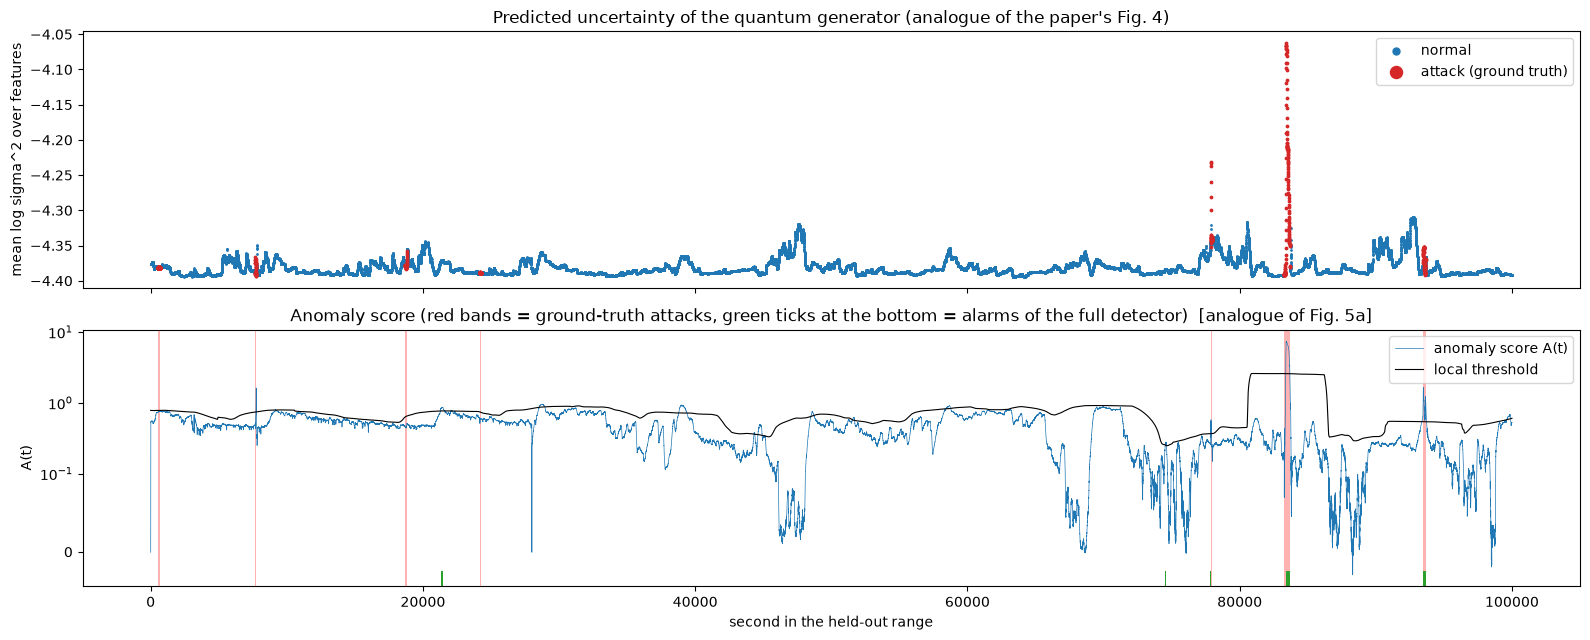

In [19]:
# AUC of the individual signals on the held-out range (does the signal itself separate attack seconds from normal ones?)
Sq = scores_of(P_held_q, X_held, RES_Q["kappa"], RES_Q["critic"]); okk = ~np.isnan(Sq["top"]) & ~np.isnan(Sq["crit"])
auc = {"interval violation S_iv": roc_auc_score(y_held[okk], Sq["iv"][okk]), "top-k reconstruction S_topk": roc_auc_score(y_held[okk], Sq["top"][okk]),
       "critic score S_critic": roc_auc_score(y_held[okk], Sq["crit"][okk]), "mean log-variance": roc_auc_score(y_held[okk], np.nanmean(P_held_q["lv"], 1)[okk]),
       "repeat-last-second error": roc_auc_score(y_held[1:][okk[1:]], recon_score(X_held[1:], X_held[:-1])[okk[1:]])}
print("ROC-AUC of single signals (attack = positive), held-out range:"); print(pd.Series(auc).round(3).to_string())
lv_mean = np.nanmean(P_held_q["lv"], 1)
print("\nmean log sigma^2: normal seconds %.3f | attack seconds %.3f" % (np.nanmean(lv_mean[(y_held == 0)]), np.nanmean(lv_mean[(y_held == 1)])))

# Fig. 4 analogue: log-variance over time, ground-truth attack seconds in red
fig, ax = plt.subplots(2, 1, figsize=(16, 6.5), sharex=True)
tt = np.arange(len(y_held)); sub = slice(None, None, 3)
b = (y_held == 0)[sub]
ax[0].scatter(tt[sub][b], lv_mean[sub][b], s=1, c="tab:blue", label="normal"); ax[0].scatter(tt[sub][~b], lv_mean[sub][~b], s=3, c="tab:red", label="attack (ground truth)")
ax[0].set_ylabel("mean log sigma^2 over features"); ax[0].legend(markerscale=5, loc="upper right"); ax[0].set_title("Predicted uncertainty of the quantum generator (analogue of the paper's Fig. 4)")
A_ = np.nan_to_num(RES_Q["A"]); ax[1].plot(tt, A_, lw=.5, c="tab:blue", label="anomaly score A(t)")
ax[1].plot(tt, local_threshold(A_, W_SIZE, K_THR), c="k", lw=.8, label="local threshold")
for r in label_ranges(y_held): ax[1].axvspan(r[0], r[1], color="red", alpha=.3, lw=0)
pr = RES_Q["preds"]["Full model"]
for r in label_ranges(pr): ax[1].axvspan(r[0], r[1], ymin=0, ymax=.06, color="tab:green", lw=0)
ax[1].set_yscale("symlog", linthresh=.1); ax[1].legend(loc="upper right"); ax[1].set_xlabel("second in the held-out range"); ax[1].set_ylabel("A(t)")
ax[1].set_title("Anomaly score (red bands = ground-truth attacks, green ticks at the bottom = alarms of the full detector)  [analogue of Fig. 5a]")
plt.tight_layout(); plt.show()


### 6.2 Reference detectors on the same ranges and the same inputs

- **Last timestep** (paper's Table II): predict `x_t = x_{t-1}`, score = top-3 squared error, same local threshold.
- **Cluster-likelihood** (paper's Table II): assign the 3-second window to the nearest of the 300 K-Means centroids (using the history part), score = negative log-likelihood of `x_t` under a diagonal Gaussian
  fitted to the targets of that cluster.
- **Classical GRU-WGAN twin**: the same generator/critic interface with `nn.GRU` and linear heads, the same training loop and the same detector (not in the paper; cheap, so several seeds).
- **Isolation Forest** on the 64-value training windows (unsupervised) with the same local threshold.
- **Random forest and SVC(rbf)**, *supervised*, trained on the **labelled validation third** (windows of 4 seconds) and applied to the held-out range: an upper reference that uses labels, which the paper's unsupervised setting does not.

In [20]:
def windows4(X):
    idx = np.arange(TAU + 1)[None, :] + np.arange(len(X) - TAU)[:, None]
    return X[idx].reshape(len(idx), -1)                                    # (T-3, 64): rows are for target seconds 3..T-1

def pad3(v, fill=np.nan):
    return np.r_[np.full(TAU, fill), v]

def file_mask(a, b):
    """True where the 3-second history lies inside the same file."""
    m = np.ones(b - a, bool)
    for f in np.unique(fid[a:b]):
        i0 = np.where(fid[a:b] == f)[0][0]; m[i0:i0 + TAU] = False
    return m

def eval_scores(S, y, w=None, k=K_THR):
    return etapr(y, detect(S, W_SIZE if w is None else w, k))

ref_rows = []
for nme, (a, b, X_, y_) in {"held": (HELD_A, HELD_B, X_held, y_held)}.items():
    m_ok = file_mask(a, b)
    # last timestep
    mu_last = np.vstack([np.full((1, N_FEAT), np.nan), X_[:-1]]); S_last = recon_score(np.nan_to_num(X_), np.nan_to_num(mu_last)); S_last[~m_ok] = np.nan
    r = eval_scores(S_last, y_); ref_rows.append(dict(model="Last timestep", **{k: r[k] for k in ("eTaP", "eTaR", "TaF1")}, AUC=roc_auc_score(y_[m_ok], S_last[m_ok])))
    # cluster likelihood
    hist = np.stack([np.vstack([np.full((TAU, N_FEAT), np.nan), X_])[i:len(X_) + i] for i in range(TAU)], 1).reshape(len(X_), -1)    # (T, 48) history of every second
    h_ok = m_ok
    cl = np.zeros(len(X_), int)
    cen_h = D["cent"][:, :TAU * N_FEAT].astype(np.float64)
    for i in range(0, len(X_), 20000):
        hh_ = np.nan_to_num(hist[i:i + 20000]); cl[i:i + 20000] = ((hh_[:, None, :] - cen_h[None]) ** 2).sum(-1).argmin(1)
    var = D["cl_var"][cl] + 1e-4; nll = 0.5 * (((X_ - D["cl_mean"][cl]) ** 2) / var + np.log(2 * np.pi * var)).sum(1); nll[~h_ok] = np.nan
    r = eval_scores(nll, y_); ref_rows.append(dict(model="Cluster-likelihood", **{k: r[k] for k in ("eTaP", "eTaR", "TaF1")}, AUC=roc_auc_score(y_[h_ok], nll[h_ok])))
    # Isolation forest on the training windows, unsupervised
    iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=-1).fit(D["Wtr_sub"])
    Wt = np.vstack([np.full((TAU, (TAU + 1) * N_FEAT), np.nan), windows4(X_)]); S_if = np.full(len(X_), np.nan)
    S_if[m_ok] = -iso.score_samples(Wt[m_ok])
    r = eval_scores(S_if, y_); ref_rows.append(dict(model="Isolation Forest (unsupervised)", **{k: r[k] for k in ("eTaP", "eTaR", "TaF1")}, AUC=roc_auc_score(y_[m_ok], S_if[m_ok])))
    # supervised: trained on the labelled validation third
    Wv = np.vstack([np.full((TAU, (TAU + 1) * N_FEAT), np.nan), windows4(Xte[:CUT])]); okv = file_mask(0, CUT)
    ytr = y_all[:CUT]; sel = np.where(okv)[0][::3]
    rf = RandomForestClassifier(n_estimators=200, max_depth=12, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample").fit(Wv[sel], ytr[sel])
    p_rf = np.zeros(len(X_)); p_rf[m_ok] = rf.predict_proba(Wt[m_ok])[:, 1]
    r = etapr(y_, p_rf > 0.5); ref_rows.append(dict(model="Random forest (supervised, labels of the validation third)", **{k: r[k] for k in ("eTaP", "eTaR", "TaF1")}, AUC=roc_auc_score(y_[m_ok], p_rf[m_ok])))
    sv = np.where(okv)[0][::25]
    svc = SVC(kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED).fit(Wv[sv], ytr[sv])
    d_sv = np.zeros(len(X_)); d_sv[m_ok] = svc.decision_function(Wt[m_ok])
    r = etapr(y_, d_sv > 0); ref_rows.append(dict(model="SVC rbf (supervised, labels of the validation third)", **{k: r[k] for k in ("eTaP", "eTaR", "TaF1")}, AUC=roc_auc_score(y_[m_ok], d_sv[m_ok])))
REF = pd.DataFrame(ref_rows).set_index("model")
display(REF.round(3).style.set_caption("reference detectors, held-out range (alarms = threshold crossings; AUC of the raw score)"))


,eTaP,eTaR,TaF1,AUC
model,,,,
Last timestep,0.034000,0.202000,0.059000,0.809000
Cluster-likelihood,0.060000,0.447000,0.106000,0.866000
Isolation Forest (unsupervised),0.060000,0.607000,0.110000,0.744000
"Random forest (supervised, labels of the validation third)",0.000000,0.000000,0.000000,0.808000
"SVC rbf (supervised, labels of the validation third)",0.061000,0.409000,0.107000,0.734000


In [21]:
# classical GRU-WGAN twin: same loop, same detector; several seeds (cheap)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
tw_rows, TWIN = [], {}
for sd in C_SEEDS:
    torch.manual_seed(sd); Gc, Dc = CGenerator(N_FEAT, HIDDEN), CCritic(N_FEAT, HIDDEN)
    t0 = time.time(); h_ = train_wgan(Gc, Dc, Wc, yc, C_STEPS, 64, LR_C, LAM_KL, LAM_GP, 1, LAM_REC, sd, log_every=C_STEPS, log=lambda s: None)
    Pv, Ph = predict_range(Gc, Dc, 0, VAL_B), predict_range(Gc, Dc, HELD_A, HELD_B)
    R_ = tune_and_eval(Pv, Ph, y_val, y_held, X_val, X_held, f"classical twin, seed {sd}")
    tw_rows.append(dict(seed=sd, mse_mu=float(np.nanmean((X_held - Ph["mu"]) ** 2)), **R_["table"].loc["Full model", ["eTaP", "eTaR", "TaF1"]].to_dict(),
                        **{"TaF1 " + k: R_["table"].loc[k, "TaF1"] for k in ("Critic only", "Reconstruction error only", "Interval violation only")}, train_s=round(time.time() - t0)))
    TWIN[sd] = R_
TW = pd.DataFrame(tw_rows).set_index("seed"); display(TW.round(3).style.set_caption("classical GRU-WGAN twin, held-out range"))
print("TaF1 mean +- std over %d seed(s): %.3f +- %.3f" % (len(TW), TW["TaF1"].mean(), TW["TaF1"].std(ddof=0)))

# the paper's literal loss (no reconstruction anchor), classical twin only: does the adversarial loss alone learn the one-step map in this budget?
torch.manual_seed(SEED); G0, D0 = CGenerator(N_FEAT, HIDDEN), CCritic(N_FEAT, HIDDEN)
h0 = train_wgan(G0, D0, Wc, yc, C_STEPS, 64, LR_C, LAM_KL, LAM_GP, 1, 0.0, SEED, log_every=C_STEPS, log=lambda s: None)
P0 = predict_range(G0, D0, HELD_A, HELD_B)
print("classical twin, lambda_rec = 0 (paper's loss only), %d steps: held-out MSE(mu) = %.4f (with the anchor: %.4f; predict-the-mean: %.4f)" % (
    C_STEPS, np.nanmean((X_held - P0["mu"]) ** 2), TW["mse_mu"].mean(), np.mean((X_held - yc.mean(0)) ** 2)))


[classical twin, seed 42] chosen on validation: kappa = 3.0, critic on the generated point


[classical twin, seed 43] chosen on validation: kappa = 2.0, critic on the observed point


[classical twin, seed 44] chosen on validation: kappa = 2.0, critic on the generated point


,mse_mu,eTaP,eTaR,TaF1,TaF1 Critic only,TaF1 Reconstruction error only,TaF1 Interval violation only,train_s
seed,,,,,,,,
42,0.005000,0.512000,0.496000,0.504000,0.154000,0.117000,0.151000,1010
43,0.005000,0.554000,0.440000,0.491000,0.167000,0.122000,0.137000,1099
44,0.005000,0.269000,0.449000,0.336000,0.190000,0.117000,0.132000,1070


TaF1 mean +- std over 3 seed(s): 0.444 +- 0.076


classical twin, lambda_rec = 0 (paper's loss only), 1500 steps: held-out MSE(mu) = 0.3059 (with the anchor: 0.0053; predict-the-mean: 0.0604)


## 8. Noisy simulation (the paper's noise model) and the sim-to-noisy transfer

The paper trains on a noisy simulator (random Pauli errors with probability 0.1 and flipped CNOTs with probability 0.2), tests on three platforms and shows that a model trained **without** noise collapses on real
hardware (Fig. 5b) while the **noisy-trained** one transfers (Fig. 5c, Table IV, on a fragment of the test set). We have no hardware, so the *noisy simulator* plays the role of the device here:

| setting | training | execution |
|---|---|---|
| (a) reference | noiseless | noiseless simulator |
| (b) analogue of Fig. 5b | noiseless | **noisy** simulator |
| (c) analogue of Fig. 5c | noise-aware fine-tuning (our budget) | **noisy** simulator |
| (d) | noise-aware fine-tuning | noiseless simulator |

The experiment runs on a **fragment** of the held-out range (like the paper's hardware run) chosen as the stretch with the largest number of attack seconds. The noisy simulator draws an independent error pattern
for every circuit evaluation (Monte-Carlo trajectories), so the numbers fluctuate with the seed.

fragment: held-out seconds [209,683, 217,683) with 2 attacks (553 attack seconds)
noise-aware fine-tuning: 20 steps


  step    1/20 | critic +8.499 (gp 0.844) | gen adv -0.395  var 0.6853  kl 0.237  mse(mu,x) 0.3255 | 12s


  step    5/20 | critic +7.120 (gp 0.687) | gen adv -0.422  var 0.5266  kl 0.195  mse(mu,x) 0.2225 | 82s


  step   10/20 | critic +5.820 (gp 0.587) | gen adv -0.387  var 0.5477  kl 0.162  mse(mu,x) 0.1718 | 151s


  step   15/20 | critic +4.249 (gp 0.407) | gen adv -0.356  var 0.5369  kl 0.180  mse(mu,x) 0.1297 | 221s


  step   20/20 | critic +5.921 (gp 0.603) | gen adv -0.294  var 0.4776  kl 0.194  mse(mu,x) 0.1143 | 283s


fragment inference for 4 settings: 540 s


,mse_mu,eTaP,eTaR,TaF1,alarms,attacks
setting,,,,,,
"(a) noiseless-trained, noiseless run",0.072000,0.861000,0.684000,0.762000,8,2
"(b) noiseless-trained, NOISY run",0.299000,0.852000,0.325000,0.470000,71,2
"(c) noise-fine-tuned, NOISY run",0.133000,1.000000,0.292000,0.452000,41,2
"(d) noise-fine-tuned, noiseless run",0.135000,0.613000,0.689000,0.648000,9,2


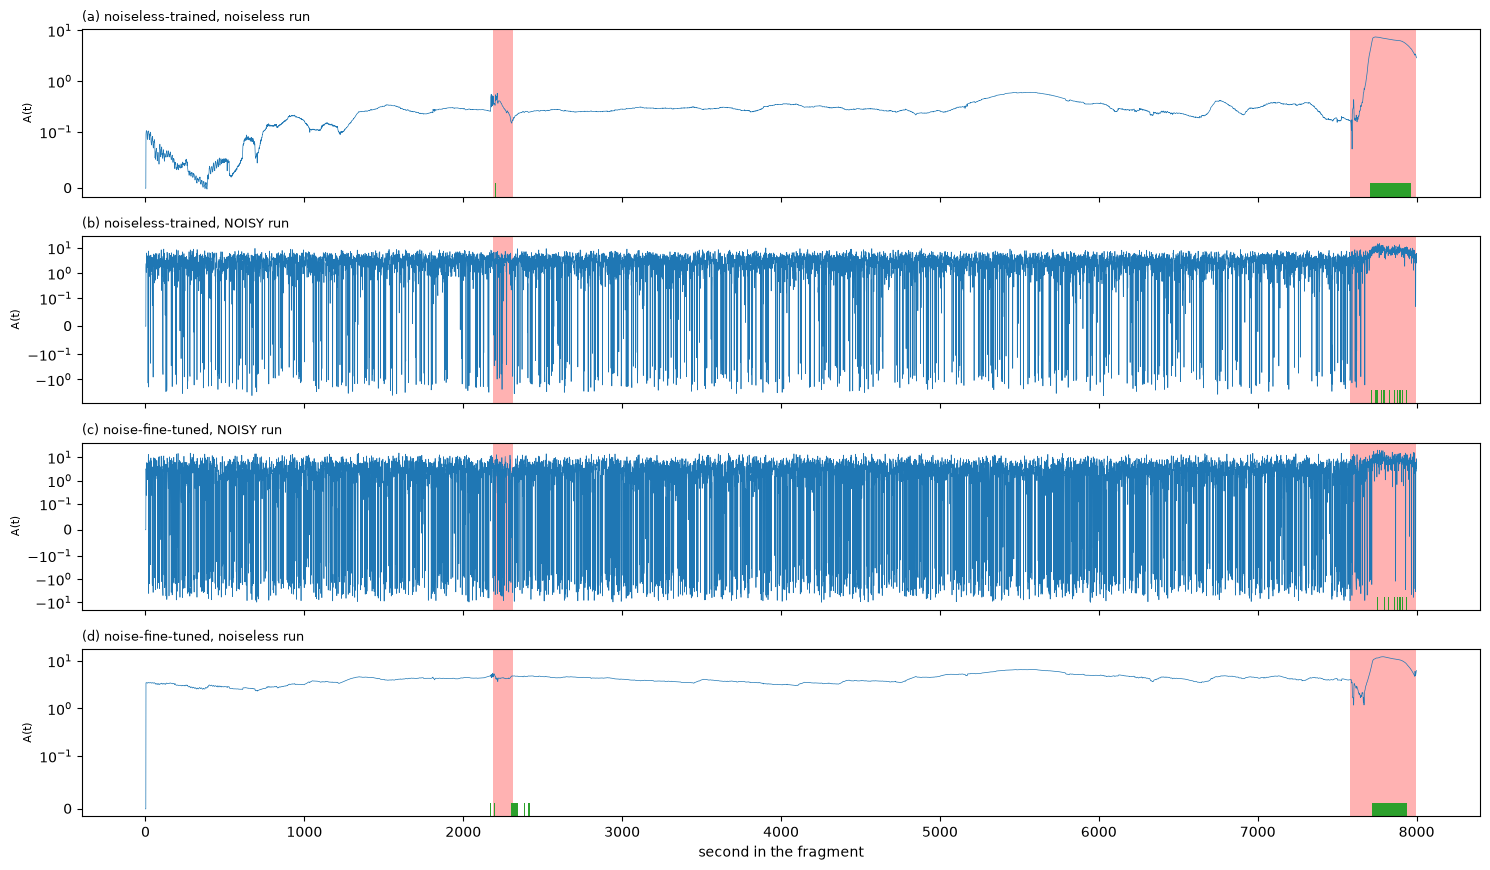

In [22]:
import copy
L = min(NOISY_SEC, len(y_held))
cs = np.r_[0, np.cumsum(y_held)]; s0 = int(np.argmax(cs[L:] - cs[:-L])) if len(cs) > L else 0
fa, fb = HELD_A + s0, HELD_A + s0 + L
X_f, y_f = Xte[fa:fb], y_all[fa:fb]
print(f"fragment: held-out seconds [{fa:,}, {fb:,}) with {len(label_ranges(y_f))} attacks ({int(y_f.sum())} attack seconds)")
# noise-aware fine-tuning: continue from the noiseless weights with the noise switched on in every circuit evaluation (CHOICE: fine-tuning, not training from scratch)
NOISE.on = True; NOISE.gen = torch.Generator().manual_seed(SEED)
G_n, D_n = copy.deepcopy(G_q), copy.deepcopy(D_q)
t0 = time.time(); print(f"noise-aware fine-tuning: {NOISY_STEPS} steps")
hist_n = train_wgan(G_n, D_n, Wc, yc, NOISY_STEPS, BATCH, LR_Q, LAM_KL, LAM_GP, 1, LAM_REC, SEED + 1, log_every=max(1, NOISY_STEPS // 4))
NOISE.on = False; TIME_N_TRAIN = time.time() - t0
settings = {"(a) noiseless-trained, noiseless run": (G_q, D_q, False), "(b) noiseless-trained, NOISY run": (G_q, D_q, True),
            "(c) noise-fine-tuned, NOISY run": (G_n, D_n, True), "(d) noise-fine-tuned, noiseless run": (G_n, D_n, False)}
Pf = {}
t0 = time.time()
for nm, (g_, d_, noisy) in settings.items():
    Pf[nm] = predict_stream(g_, d_, X_f, noisy=noisy, seed=SEED + 7)
print(f"fragment inference for 4 settings: {time.time() - t0:.0f} s")
# the choices (kappa, critic, normalisation) are those fixed on the noiseless validation range
Sv0 = scores_of(P_val_q, X_val, RES_Q["kappa"], RES_Q["critic"]); NORM0 = norm_from(Sv0)
noisy_rows, A_f = [], {}
for nm, P in Pf.items():
    Sc = scores_of(P, X_f, RES_Q["kappa"], RES_Q["critic"]); pr_, A_ = variants(Sc, NORM0, w=min(W_SIZE, len(y_f) // 2)); A_f[nm] = (A_, pr_["Full model"])
    noisy_rows.append(row(y_f, pr_["Full model"], setting=nm, mse_mu=float(np.nanmean((X_f - P["mu"]) ** 2))))
NOISY = pd.DataFrame(noisy_rows).set_index("setting"); display(NOISY.round(3).style.set_caption("noisy-simulator experiment on the fragment (full detector)"))
fig, ax = plt.subplots(len(Pf), 1, figsize=(15, 2.2 * len(Pf)), sharex=True)
for a, (nm, (A_, pr_)) in zip(ax, A_f.items()):
    a.plot(np.nan_to_num(A_), lw=.5); a.set_yscale("symlog", linthresh=.1); a.set_ylabel("A(t)", fontsize=8); a.set_title(nm, fontsize=9, loc="left")
    for r in label_ranges(y_f): a.axvspan(r[0], r[1], color="red", alpha=.3, lw=0)
    for r in label_ranges(pr_): a.axvspan(r[0], r[1], ymin=0, ymax=.08, color="tab:green", lw=0)
ax[-1].set_xlabel("second in the fragment"); plt.tight_layout(); plt.show()


## 9. Real IBM Quantum hardware (Table IV and Fig. 5b/c of the paper)

The paper runs the trained generator-critic pair on a real IBM device for a fragment of the test sequence. That needs queue time on a quantum computer and about 24 circuits per second of data, so this notebook
does **not** do it; the claim is marked "cannot be checked" and section 8 gives the noisy-simulator stand-in. If you have an IBM token you could transpile the circuit of the architecture section for the device
and run it through `qiskit-ibm-runtime`; `IBM_TOKEN` in the configuration cell is only a placeholder for that exercise.

In [23]:
if IBM_TOKEN:
    print("IBM_TOKEN is set, but the hardware run is not implemented in this notebook (see the exercises).")
else:
    print("IBM_TOKEN is empty: hardware cells skipped (the paper's Table IV cannot be checked here).")


IBM_TOKEN is empty: hardware cells skipped (the paper's Table IV cannot be checked here).


## 10. Side by side with the paper

Verdict rule for a number: **reproduced** when our value is within 0.02 of the paper's (eTaP / eTaR / TaF1), otherwise **not reached** or **exceeded** with the gap.
Boolean claims are "reproduced" when the observed ordering agrees. Our numbers come from the quantum model of section 4 (noiseless simulator), evaluated on the ranges printed in section 5,
with the choices listed at the top. Claims about real hardware or other people's trained models **cannot be checked** here.

In [24]:
def verdict_num(paper, ours, tol=0.02):
    if np.isnan(ours): return "cannot be checked"
    d = ours - paper
    return "reproduced" if abs(d) <= tol else (f"exceeded (+{d:.2f})" if d > 0 else f"not reached ({d:.2f})")
def verdict_bool(ok): return "reproduced" if ok else "not reproduced"
tq = RES_Q["table"]; rows = []
def num(claim, paper, ours, where="held-out range"): rows.append(dict(claim=claim, paper=paper, notebook=round(float(ours), 3), verdict=verdict_num(paper, ours), note=where))
def flag(claim, paper, ours_txt, ok, where="held-out range"): rows.append(dict(claim=claim, paper=paper, notebook=ours_txt, verdict=verdict_bool(ok), note=where))
def cannot(claim, paper, why): rows.append(dict(claim=claim, paper=paper, notebook="-", verdict="cannot be checked", note=why))

num("Table II  QWGAN noiseless: TaF1", 0.89, tq.loc["Full model", "TaF1"]); num("Table II  QWGAN noiseless: eTaP", 0.93, tq.loc["Full model", "eTaP"]); num("Table II  QWGAN noiseless: eTaR", 0.85, tq.loc["Full model", "eTaR"])
fr = NOISY.loc["(c) noise-fine-tuned, NOISY run"]
num("Table II  QWGAN noisy simulator: TaF1", 0.78, fr.TaF1, "fragment of the held-out range, noise-fine-tuned model run on the noisy simulator")
num("Table II  QWGAN noisy simulator: eTaP", 0.85, fr.eTaP, "same fragment"); num("Table II  QWGAN noisy simulator: eTaR", 0.73, fr.eTaR, "same fragment")
num("Table II  last timestep: TaF1", 0.04, REF.loc["Last timestep", "TaF1"]); num("Table II  last timestep: eTaP", 0.03, REF.loc["Last timestep", "eTaP"]); num("Table II  last timestep: eTaR", 0.09, REF.loc["Last timestep", "eTaR"])
num("Table II  cluster-likelihood: TaF1", 0.23, REF.loc["Cluster-likelihood", "TaF1"]); num("Table II  cluster-likelihood: eTaP", 0.48, REF.loc["Cluster-likelihood", "eTaP"]); num("Table II  cluster-likelihood: eTaR", 0.15, REF.loc["Cluster-likelihood", "eTaR"])
num("Table III ablation, critic only: TaF1", 0.77, tq.loc["Critic only", "TaF1"]); num("Table III ablation, reconstruction only: TaF1", 0.78, tq.loc["Reconstruction error only", "TaF1"])
num("Table III ablation, interval violation only: TaF1", 0.88, tq.loc["Interval violation only", "TaF1"])
others = tq.drop(index="Full model")["TaF1"].max()
flag("Text: the full multi-signal model is the best of its four variants", "0.89 > 0.88, 0.78, 0.77", f"full {tq.loc['Full model', 'TaF1']:.3f} vs best other {others:.3f}", tq.loc["Full model", "TaF1"] >= others)
flag("Text: QWGAN beats last-timestep and cluster-likelihood", "0.89 > 0.23 > 0.04", f"{tq.loc['Full model', 'TaF1']:.3f} vs {REF.loc['Cluster-likelihood', 'TaF1']:.3f} / {REF.loc['Last timestep', 'TaF1']:.3f}",
     tq.loc["Full model", "TaF1"] > max(REF.loc["Cluster-likelihood", "TaF1"], REF.loc["Last timestep", "TaF1"]))
flag("Text: QWGAN beats the RNN baselines", "0.89 > 0.83 (RNNv1), 0.78 (RNNv2)", f"{tq.loc['Full model', 'TaF1']:.3f}", tq.loc["Full model", "TaF1"] > 0.83)
mlv_a, mlv_n = np.nanmean(lv_mean[y_held == 1]), np.nanmean(lv_mean[y_held == 0])
flag("Fig. 4: predicted log-variance is higher during attacks", "visible spikes during attacks", f"mean log s^2: attack {mlv_a:.3f} vs normal {mlv_n:.3f}; AUC {auc['mean log-variance']:.2f}", mlv_a > mlv_n and auc["mean log-variance"] > 0.55)
fa_ = NOISY.loc["(a) noiseless-trained, noiseless run", "TaF1"]; fb_ = NOISY.loc["(b) noiseless-trained, NOISY run", "TaF1"]; fc_ = NOISY.loc["(c) noise-fine-tuned, NOISY run", "TaF1"]
flag("Fig. 5: noise-trained model transfers to a noisy device better than the noiseless-trained one", "5c good, 5b collapses", f"TaF1 (b) {fb_:.3f} vs (c) {fc_:.3f}  (a: {fa_:.3f})", fc_ > fb_, "fragment, noisy simulator instead of hardware")
cannot("Table IV: real IBM hardware TaF1 0.974 (vs 0.992 simulator)", "0.974 / 0.992", "no quantum hardware used; noisy-simulator stand-in in section 8")
cannot("Table II: RNNv1 / RNNv2 baselines 0.83 / 0.78", "0.83 / 0.78", "values quoted from another paper; the published predictions re-scored in section 2 are for another HAI version")
tw = TW["TaF1"].mean()
rows.append(dict(claim="(not in the paper) classical GRU-WGAN twin, same detector: TaF1", paper="-", notebook=round(float(tw), 3), verdict="extra", note="mean over %d seed(s)" % len(TW)))
COMP = pd.DataFrame(rows); pd.set_option("display.width", 250, "display.max_colwidth", 110)
display(COMP.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print("\nverdicts:", COMP.verdict.str.split(" ").str[0].value_counts().to_dict())
print(f"quantum training {TIME_Q_TRAIN / 60:.1f} min ({Q_STEPS} steps), inference {TIME_Q_PRED / 60:.1f} min, noisy fine-tuning {TIME_N_TRAIN / 60:.1f} min ({NOISY_STEPS} steps)")


claim,paper,notebook,verdict,note
Table II QWGAN noiseless: TaF1,0.890000,0.507000,not reached (-0.38),held-out range
Table II QWGAN noiseless: eTaP,0.930000,0.627000,not reached (-0.30),held-out range
Table II QWGAN noiseless: eTaR,0.850000,0.426000,not reached (-0.42),held-out range
Table II QWGAN noisy simulator: TaF1,0.780000,0.452000,not reached (-0.33),"fragment of the held-out range, noise-fine-tuned model run on the noisy simulator"
Table II QWGAN noisy simulator: eTaP,0.850000,1.000000,exceeded (+0.15),same fragment
Table II QWGAN noisy simulator: eTaR,0.730000,0.292000,not reached (-0.44),same fragment
Table II last timestep: TaF1,0.040000,0.059000,reproduced,held-out range
Table II last timestep: eTaP,0.030000,0.034000,reproduced,held-out range
Table II last timestep: eTaR,0.090000,0.202000,exceeded (+0.11),held-out range
Table II cluster-likelihood: TaF1,0.230000,0.106000,not reached (-0.12),held-out range



verdicts: {'not': 12, 'reproduced': 5, 'exceeded': 3, 'cannot': 2, 'extra': 1}
quantum training 34.1 min (100 steps), inference 8.4 min, noisy fine-tuning 4.7 min (20 steps)


## Reading the paper critically

**What this run found** (full run, held-out range of 100,000 s with 7 attacks; numbers are those printed above).

- **The headline number is not reached.** The quantum QGRU-WGAN with the paper's two-stage detector gives eTaP 0.63, eTaR 0.43, **TaF1 0.51** (19 alarms for 7 attacks) against the paper's 0.93 / 0.85 / 0.89. The classical GRU-WGAN twin with the same detector reaches TaF1 0.44 +- 0.08 over three seeds (0.50, 0.49, 0.34), so **we see no quantum advantage**; the single quantum run is inside the spread of the classical seeds.
- **What does carry over qualitatively.** (i) The *last-timestep* baseline is as bad as the paper says (TaF1 0.06 against 0.04), although its raw error score separates attacks from normal seconds reasonably (ROC-AUC 0.81): the metric punishes the many short, fragmented alarms. (ii) The *gated multi-signal detector is much better than each of its parts alone* (0.51 against 0.14 to 0.16 for interval-only, reconstruction-only and critic-only), the same ordering as the paper's Table III, but at a much lower level and with a far larger gap than the paper's 0.89 against 0.77 to 0.88. (iii) The predicted log-variance is slightly higher during attacks (ROC-AUC 0.70, mean -4.34 against -4.38), a weak version of Fig. 4.
- **The generator is a poor forecaster.** After 100 steps the quantum generator's one-step error is 0.030, only about half of the predict-the-mean error (0.060) and ~1000 times the error of simply repeating the last second (3e-5; HAI changes slowly). The classical twin reaches 0.005. Detection therefore works mostly as *novelty detection* (distance of the observation from what the generator regards as normal), not as precise forecasting. The cluster-likelihood baseline (which is only a lookup of 300 centroids) has a higher raw AUC (0.87) than any of the generator-based signals (0.70 to 0.75).
- **The paper's literal loss does not learn the map in our budget.** With `lambda_rec = 0` the classical twin ends at MSE 0.31 after 1500 steps, *worse than predicting the mean* (0.060), against 0.005 with the reconstruction anchor that we added. Either the paper trains much longer, uses a different parametrisation (e.g. a residual output) or the KL/variance terms play a role that the text does not reveal. Our anchor is therefore a necessary, documented deviation, not a harmless detail.
- **The noisy-simulator story is not confirmed.** Under the paper's noise model (Pauli errors with probability 0.1 per qubit after every encoding and every rotation layer, 12 layers per circuit) the noiseless-trained model degrades from TaF1 0.76 to 0.47 on a 8,000-second fragment with 2 attacks, but 20 steps of noise-aware fine-tuning did not help (0.45; 0.65 when that model is run without noise). The paper trains from scratch and reports TaF1 0.78 on the full test set; our budget cannot show whether that is reachable. The real-hardware claim of Table IV (0.974) **cannot be checked**; note that it is computed on a hand-picked "representative fragment containing a known attack", where the simulator reaches 0.992, so it says little about the whole test set.

**Reading the paper critically.**

1. *Dataset description is internally inconsistent.* "Version 21.03" has 79 numeric columns, 50 attack intervals and 1 reading per second; the quoted "86 features", "38 attacks / 14 primitives" and "59 measurements per second" belong to other versions (or are wrong). The reader cannot know which split and which attacks were scored.
2. *Many details that decide the result are missing:* the number of training steps/epochs, batch size, optimiser, `kappa`, `lambda_kl`, `lambda_gp`, the QGRU hidden size, the exact encoding (Table I says `arccos(x)`, Fig. 2 says `arctan(h)`), the critic score (Eq. 2 uses the *generated* point although the text speaks of "fake-looking" samples), and the way the window `w` enters the local threshold. We made each choice explicit; with all of them open, the 0.89 is not a reproducible target.
3. *The window size `w = mu_d^p g^(1-p)` is dominated by `g`* (the mean gap between attacks): here `w` = 5645 s for attacks of ~170 s, i.e. a local threshold computed over more than an hour. That makes the detector fire a handful of times per hour, which is what the eTaPR metric rewards, but it also means the metric partly measures the thresholding scheme rather than the quantum model.
4. *The evaluation is statistically thin.* Our held-out range has 7 attacks; moving one alarm range changes TaF1 by several points (the three classical seeds span 0.34 to 0.50). The paper reports one number without spread, for a model trained on 300 centroids.
5. *The 5-qubit hybrid layers pass only five expectation values to the next dense layer*, a rank-5 bottleneck for 16 correlated sensors; with our budget this is what limits the forecast, not the gate structure. The "quantum-enhanced expressiveness" argument is not tested against a classical layer of equal width; our classical twin (2,176 against 4,770 generator parameters) does at least as well.
6. *Simulation cost is the practical limit:* about 24 five-qubit circuits per second of data, i.e. minutes per 10,000 s on a CPU. The paper's 0.89 requires evaluating hundreds of thousands of seconds, which is feasible only with a fast simulator; our exact simulator is asserted equal to PennyLane but not fast.


## Exercises

1. **Residual generator.** Change the generator so that `mu_t = x_{t-1} + head(h)` (the head predicts the *change*). The one-step error of the persistence baseline is more than 100 times smaller than the error of our generators.
   What happens to the TaF1 of the full detector, and does it still beat the "last timestep" baseline? Is the quantum part still needed?
2. **The paper's literal loss.** Set `LAM_REC = 0` and train the quantum model for as many steps as you can afford (the classical twin can do thousands). Does the adversarial loss alone learn the next-step map? Track `MSE(mu, x)` against the predict-the-mean value.
3. **Qubits and bottleneck.** Every hybrid layer hands only five expectation values to the next dense layer. Change `NQ` (the sizes of the dense layers and the injection pattern follow) to 3, 5 and 8 and compare accuracy of `mu` against the cost of the simulation.
4. **Noise.** Vary the Pauli-error probability of the noise model (0.01, 0.1, 0.2) and train from scratch on the noisy simulator instead of fine-tuning. How does the gap between the noiseless-trained and the noise-trained model in section 8 change?
5. **Hardware.** Pick the smallest trained circuit (one hybrid layer), transpile the PennyLane circuit of the architecture section to a real backend with `qiskit-ibm-runtime`, run a few hundred shots, and compare the five `<Z>` values with the simulator. How many two-qubit gates does the CNOT ring need on a heavy-hex device?